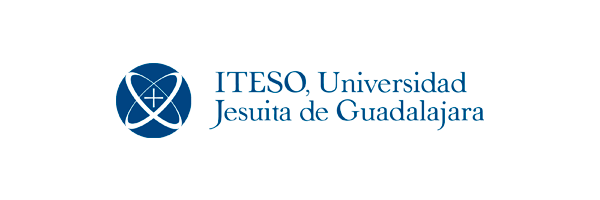

# Reporte de Prácticas de Redes Competitivas

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 6 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 1: red competitiva programada desde cero](#practica1)
    - 2.1 [Definición del problema](#p1-definicion)
    - 2.2 [Descripción del algoritmo](#p1-algoritmo)
    - 2.3 [Implementación](#p1-implementacion)
    - 2.4 [Pruebas y resultados](#p1-pruebas)
3. [Práctica 2: red competitiva con MiniSom](#practica2)
    - 3.1 [Definición del problema](#p2-definicion)
    - 3.2 [Descripción del algoritmo](#p2-algoritmo)
    - 3.3 [Implementación](#p2-implementacion)
    - 3.4 [Pruebas y resultados](#p2-pruebas)
4. [Práctica 3: agrupamiento de activos de la BMV](#practica3)
5. [Práctica 4: patrones en una serie de tiempo del activo BMV_24](#practica4)
    - 5.1 [Definición del problema](#p4-definicion)
    - 5.2 [Descripción del algoritmo](#p4-algoritmo)
    - 5.3 [Implementación](#p4-implementacion)
    - 5.4 [Pruebas y resultados](#p4-pruebas)
    - 5.5 [Conclusiones de la práctica](#p4-conclusiones)
6. [Conclusiones](#conclusiones)
    - 6.1 [Conclusiones personales](#conclusiones-personales)
    - 6.2 [Conclusiones generales](#conclusiones-generales)


<a id="introduccion"></a>

## 1. Introducción y objetivos

Las redes que usamos antes (ADALINE y perceptrón) aprenden con **aprendizaje supervisado**: cada dato trae la respuesta correcta y la red corrige sus pesos según el error. Una **red competitiva** aprende de forma **no supervisada**: los datos no traen etiqueta y la red tiene que descubrir sola qué grupos existen.

La idea es sencilla. Cada neurona tiene un vector de pesos que funciona como un "punto" en el mismo espacio que los datos. Cuando llega un dato, todas las neuronas **compiten** y gana la que está más cerca (menor distancia euclidiana). Solo la ganadora se actualiza y se acerca un poco al dato (*winner takes all*). Después de repetir esto muchas veces, cada neurona termina en el centro de un grupo de datos, y la red sirve para agrupar (*clustering*) y para decir a qué grupo pertenece un dato nuevo.

**Objetivo general:** implementar una red competitiva y usarla para encontrar los grupos que hay en un conjunto de datos sin etiquetas.

**Objetivos específicos**
- Programar desde cero la regla de aprendizaje competitivo y ver cómo se mueven los pesos durante el entrenamiento (Práctica 1).
- Usar la red entrenada para clasificar un dato nuevo.
- Revisar cómo cambian los resultados con el número de neuronas y la tasa de aprendizaje.
- Resolver un problema con más grupos usando la librería MiniSom (Práctica 2).
- Agrupar 35 activos de la Bolsa Mexicana de Valores según el comportamiento de sus precios (Práctica 3).

<a id="practica1"></a>

## 2. Práctica 1: red competitiva programada desde cero

<a id="p1-definicion"></a>

### 2.1 Definición del problema

El archivo `datos1.txt` contiene puntos en dos dimensiones $(x_1, x_2)$ **sin etiqueta de grupo**. En la gráfica se ve que forman **4 nubes** separadas. Se busca:

1. Entrenar una red competitiva de **4 neuronas** (una por grupo) para que cada neurona se ubique en el centro de un grupo.
2. Asignar cada punto al grupo de su neurona ganadora.
3. Usar la red entrenada para decir a qué grupo pertenece el dato nuevo $(0, 8)$.

<a id="p1-algoritmo"></a>

### 2.2 Descripción del algoritmo

1. **Inicialización:** se crean los pesos $W$ de las $n$ neuronas con valores aleatorios entre 0 y 1. Cada columna de $W$ es la posición de una neurona.
2. **Competencia:** para cada dato $x$ se calcula su distancia a cada neurona, $d_j = \lVert x - w_j \rVert^2$, y gana la más cercana: $g = \arg\min_j d_j$.
3. **Actualización (regla de Kohonen):** solo la ganadora se acerca al dato:
$$w_g \leftarrow w_g + \alpha\,(x - w_g)$$
   donde $\alpha$ es la tasa de aprendizaje. Con $\alpha = 0.1$, la neurona recorre el 10 % de la distancia que la separa del dato.
4. **Repetición:** se recorren todos los datos durante varias épocas, hasta que los pesos casi no se mueven.
5. **Clasificación:** cada dato, nuevo o de entrenamiento, pertenece al grupo de la neurona más cercana. La salida de la red es un vector *one-hot*: 1 en la neurona ganadora y 0 en las demás.

**Pseudocódigo**
```
INICIO
    Leer datos1.txt -> X (2 x m)
    W <- valores aleatorios en [0, 1)        // 2 x n, una columna por neurona
    PARA época = 1 HASTA 25 HACER
        PARA cada dato x en X HACER
            d_j <- || x - w_j ||^2  para j = 1..n
            g   <- índice del menor d_j       // neurona ganadora
            w_g <- w_g + alpha * (x - w_g)    // solo se mueve la ganadora
        FIN PARA
    FIN PARA
    Para cada dato: grupo <- neurona más cercana
    Para el dato nuevo (0, 8): salida one-hot de la neurona ganadora
FIN
```

<a id="p1-implementacion"></a>

### 2.3 Implementación

**a) Librerías y carga de datos**

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Cargar los datos (cada columna es un punto y cada fila una variable)
data = np.loadtxt("datos1.txt", delimiter=",")
if data.shape[0] > data.shape[1]:      # Si viene con un punto por fila, se transpone
    data = data.T

print(f"Variables: {data.shape[0]} | Puntos: {data.shape[1]}")
print(f"Rango x1: [{data[0].min():.2f}, {data[0].max():.2f}] | Rango x2: [{data[1].min():.2f}, {data[1].max():.2f}]")

Variables: 2 | Puntos: 200
Rango x1: [-1.94, 11.88] | Rango x2: [-5.95, 11.84]


**b) Funciones de la red**

In [38]:
def neurona_ganadora(x, W):
    # Distancia euclidiana al cuadrado entre el dato x y cada neurona (columna de W)
    distancias = np.sum((x.reshape(-1, 1) - W) ** 2, axis=0)
    return np.argmin(distancias), distancias


def entrenar_competitiva(data, nn, alpha, epocas, semilla=0):
    # Entrena la red: regresa pesos finales, pesos iniciales e historial por época
    rng = np.random.default_rng(semilla)          # Semilla fija para repetir resultados
    W = rng.random((data.shape[0], nn))           # Pesos aleatorios en [0, 1)
    W0 = W.copy()
    historial = [W.copy()]
    for _ in range(epocas):
        for k in range(data.shape[1]):
            x = data[:, k]
            g, _ = neurona_ganadora(x, W)
            W[:, g] = W[:, g] + alpha * (x - W[:, g])   # Solo se actualiza la ganadora
        historial.append(W.copy())
    return W, W0, np.array(historial)


def asignar_grupos(data, W):
    # Grupo de cada punto = neurona más cercana
    return np.array([neurona_ganadora(data[:, k], W)[0] for k in range(data.shape[1])])

**c) Entrenamiento** (4 neuronas, α = 0.1, 25 épocas)

In [39]:
nn = 4          # Una neurona por grupo
alpha = 0.1     # Tasa de aprendizaje
epocas = 25

W, W0, historial = entrenar_competitiva(data, nn, alpha, epocas)
grupos = asignar_grupos(data, W)

print("Pesos iniciales (W0):")
print(np.round(W0, 4))
print("\nPesos finales (W) - cada columna es una neurona:")
print(np.round(W, 4))

Pesos iniciales (W0):
[[0.637  0.2698 0.041  0.0165]
 [0.8133 0.9128 0.6066 0.7295]]

Pesos finales (W) - cada columna es una neurona:
[[10.1856  7.4232  3.8061  0.2079]
 [ 9.7691  2.1977 -4.1453  5.6714]]


<a id="p1-pruebas"></a>

### 2.4 Pruebas y resultados

**a) Movimiento de las neuronas y grupos encontrados**

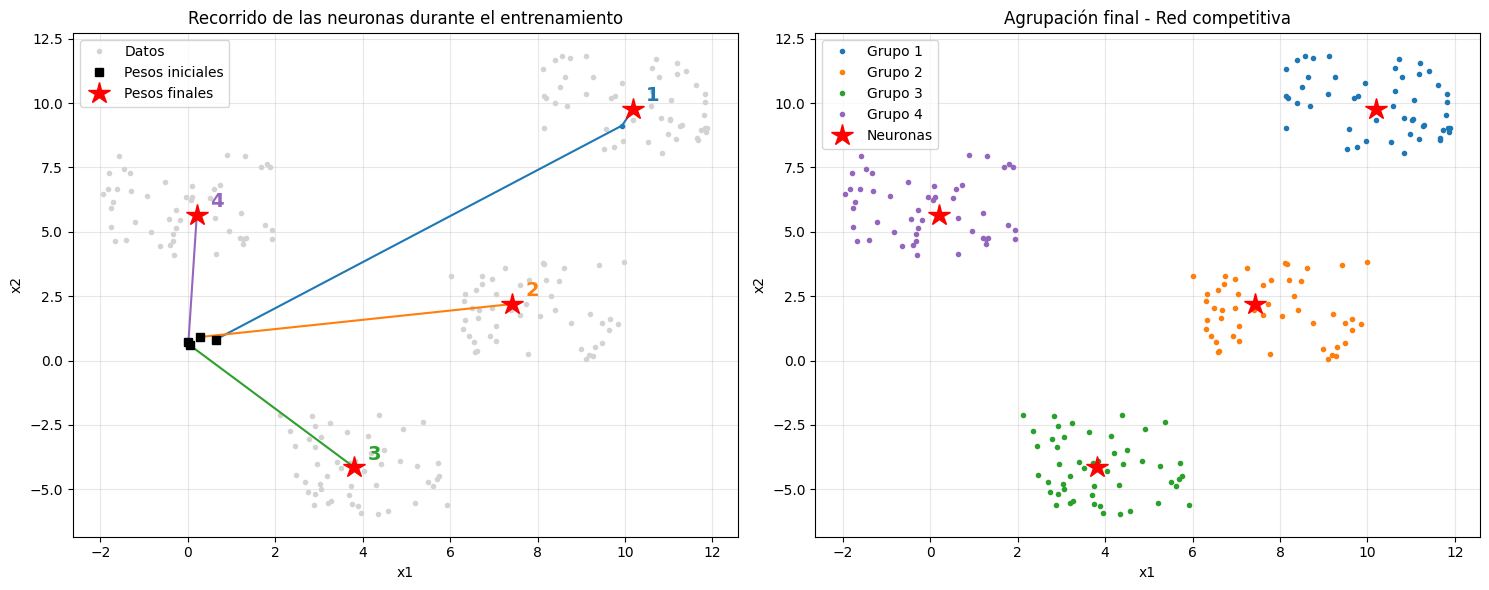

In [40]:
colores = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink"]
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Izquierda: recorrido de cada neurona desde su posición inicial
axs[0].plot(data[0], data[1], ".", color="lightgray", label="Datos")
for j in range(nn):
    axs[0].plot(historial[:, 0, j], historial[:, 1, j], "-o", ms=3, color=colores[j])
    axs[0].text(W[0, j] + 0.3, W[1, j] + 0.3, str(j + 1), fontsize=14, fontweight="bold", color=colores[j])
axs[0].plot(W0[0], W0[1], "ks", ms=6, label="Pesos iniciales")
axs[0].plot(W[0], W[1], "r*", ms=16, label="Pesos finales")
axs[0].set(title="Recorrido de las neuronas durante el entrenamiento", xlabel="x1", ylabel="x2")
axs[0].legend(); axs[0].grid(alpha=0.3)

# Derecha: datos coloreados según su neurona ganadora
for j in range(nn):
    axs[1].plot(data[0, grupos == j], data[1, grupos == j], ".", color=colores[j], label=f"Grupo {j + 1}")
axs[1].plot(W[0], W[1], "r*", ms=16, label="Neuronas")
axs[1].set(title="Agrupación final - Red competitiva", xlabel="x1", ylabel="x2")
axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**b) Convergencia:** cuánto se mueven los pesos en cada época

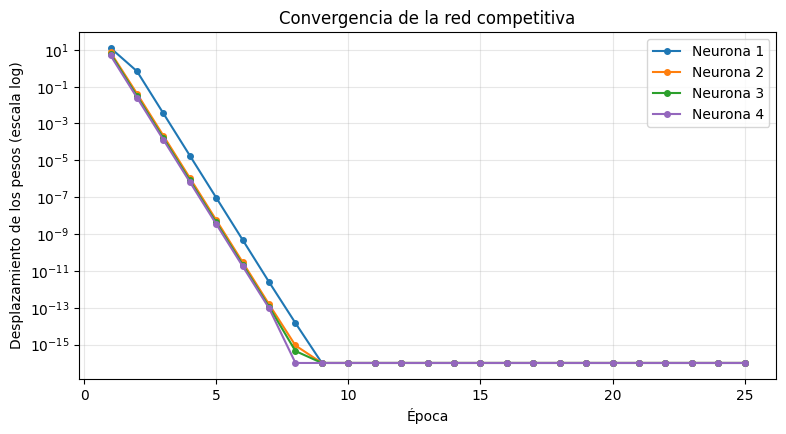

,Neurona,Peso final x1,Peso final x2,Puntos asignados,Centro real x1,Centro real x2
0,1,10.186,9.769,50,10.264,9.960
1,2,7.423,2.198,50,7.802,1.938
2,3,3.806,-4.145,50,3.857,-4.179
3,4,0.208,5.671,50,-0.077,5.903


In [41]:
movimiento = np.linalg.norm(np.diff(historial, axis=0), axis=1)   # Desplazamiento de cada neurona por época
movimiento = np.maximum(movimiento, 1e-16)                         # Evita log(0) cuando ya no se mueven

plt.figure(figsize=(9, 4.5))
for j in range(nn):
    plt.semilogy(range(1, epocas + 1), movimiento[:, j], "-o", ms=4, color=colores[j], label=f"Neurona {j + 1}")
plt.xlabel("Época"); plt.ylabel("Desplazamiento de los pesos (escala log)")
plt.title("Convergencia de la red competitiva")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

# Resumen por grupo
resumen = pd.DataFrame({
    "Neurona": range(1, nn + 1),
    "Peso final x1": W[0].round(3),
    "Peso final x2": W[1].round(3),
    "Puntos asignados": [int((grupos == j).sum()) for j in range(nn)],
    "Centro real x1": [data[0, grupos == j].mean().round(3) for j in range(nn)],
    "Centro real x2": [data[1, grupos == j].mean().round(3) for j in range(nn)]})
resumen

**c) Clasificación del dato nuevo $(0, 8)$**

In [42]:
test = np.array([0, 8])
idx, distancias_test = neurona_ganadora(test, W)

# Vector de salida one-hot: 1 en la neurona ganadora
salida = np.zeros((nn, 1))
salida[idx, 0] = 1

print(f"Distancias del dato {test} a cada neurona: {np.round(distancias_test, 4)}")
print(f"Neurona ganadora: {idx + 1}")
print("Salida de la red (one-hot):")
print(salida)

Distancias del dato [0 8] a cada neurona: [106.8768  88.7699 161.9944   5.4658]
Neurona ganadora: 4
Salida de la red (one-hot):
[[0.]
 [0.]
 [0.]
 [1.]]


**d) Pruebas con distinto número de neuronas y tasa de aprendizaje**

Se repite el entrenamiento (25 épocas, misma semilla) cambiando $n$ y $\alpha$. Para cada caso se reportan las **neuronas muertas** (las que nunca ganan y se quedan sin datos) y el **error de cuantización**, que es la distancia promedio de cada punto a su neurona; entre menor sea, mejor representan las neuronas a los datos.

In [43]:
def evaluar_caso(nn_c, alpha_c, epocas_c=25):
    W_c, _, _ = entrenar_competitiva(data, nn_c, alpha_c, epocas_c)
    g_c = asignar_grupos(data, W_c)
    error = np.mean(np.linalg.norm(data - W_c[:, g_c], axis=0))
    return {"Neuronas": nn_c, "alpha": alpha_c,
            "Neuronas muertas": int(sum((g_c == j).sum() == 0 for j in range(nn_c))),
            "Puntos por neurona": [int((g_c == j).sum()) for j in range(nn_c)],
            "Error de cuantización": round(error, 4)}

casos = [(4, 0.01), (4, 0.1), (4, 0.5), (3, 0.1), (5, 0.1), (6, 0.1)]
tabla_casos = pd.DataFrame([evaluar_caso(n_c, a_c) for n_c, a_c in casos])
tabla_casos.index = [f"Caso {i}" for i in range(1, len(casos) + 1)]
tabla_casos

,Neuronas,alpha,Neuronas muertas,Puntos por neurona,Error de cuantización
Caso 1,4,0.01,1,"[55, 50, 95, 0]",2.6851
Caso 2,4,0.10,0,"[50, 50, 50, 50]",1.5138
Caso 3,4,0.50,0,"[50, 50, 50, 50]",1.7362
Caso 4,3,0.10,0,"[50, 85, 65]",2.8570
Caso 5,5,0.10,1,"[50, 50, 50, 0, 50]",1.5138
Caso 6,6,0.10,2,"[50, 0, 0, 50, 50, 50]",1.5138


In [44]:
# Resumen de resultados en palabras
print("RESUMEN DE LA PRÁCTICA 1")
dist_centro = np.linalg.norm(W - np.vstack((resumen["Centro real x1"], resumen["Centro real x2"])), axis=0)
print(f"- Cada neurona quedó a {dist_centro.min():.3f}-{dist_centro.max():.3f} unidades del centro de su grupo.")
print(f"- Puntos por grupo: {resumen['Puntos asignados'].tolist()}.")
mov_max = movimiento.max(axis=1)
estable = np.argmax(mov_max < 1e-3) + 1 if (mov_max < 1e-3).any() else None
print(f"- Los pesos se movieron menos de 0.001 a partir de la época {estable}." if estable
      else "- Los pesos todavía se movían al terminar las épocas.")
print(f"- El dato nuevo {test} quedó en el grupo de la neurona {idx + 1}, cuyo peso es ({W[0, idx]:.2f}, {W[1, idx]:.2f}).")
mejor = tabla_casos.loc[tabla_casos["Neuronas muertas"] == 0, "Error de cuantización"].idxmin()
print(f"- En la tabla de casos, el menor error sin neuronas muertas es el {mejor} "
      f"({tabla_casos.loc[mejor, 'Neuronas']} neuronas, alpha = {tabla_casos.loc[mejor, 'alpha']}).")
muertas = tabla_casos[tabla_casos["Neuronas muertas"] > 0]
if len(muertas):
    print(f"- Casos con neuronas muertas: {', '.join(muertas.index)}.")

RESUMEN DE LA PRÁCTICA 1
- Cada neurona quedó a 0.061-0.459 unidades del centro de su grupo.
- Puntos por grupo: [50, 50, 50, 50].
- Los pesos se movieron menos de 0.001 a partir de la época 4.
- El dato nuevo [0 8] quedó en el grupo de la neurona 4, cuyo peso es (0.21, 5.67).
- En la tabla de casos, el menor error sin neuronas muertas es el Caso 2 (4 neuronas, alpha = 0.1).
- Casos con neuronas muertas: Caso 1, Caso 5, Caso 6.


**Análisis**
- **Agrupación:** con 4 neuronas y α = 0.1, cada neurona termina prácticamente en el centro de una de las 4 nubes. Su peso final coincide con el promedio de los puntos de su grupo (tabla del inciso b), y el resultado es igual al que darían los centroides de los grupos, aunque la red nunca vio etiquetas.
- **Recorrido:** todos los pesos empiezan juntos cerca del origen porque se inician entre 0 y 1. Las neuronas que ganan los primeros datos se mueven primero. Una neurona puede pasar por un grupo antes de llegar al suyo si otra neurona termina "ganándole" ese grupo.
- **Convergencia:** el desplazamiento cae muy rápido. Después de pocas épocas los pesos casi no cambian, así que 25 épocas son más que suficientes.
- **Dato nuevo (0, 8):** la red activa una sola neurona (salida one-hot), la del grupo de arriba a la izquierda, que es el más cercano a ese punto.
- **Número de neuronas:** con menos neuronas que grupos (3), una neurona tiene que cubrir dos nubes y queda en medio de ellas, por eso el error sube. Con más neuronas que grupos, las sobrantes nunca ganan (**neuronas muertas**) o parten un grupo en dos. Hay que elegir tantas neuronas como grupos.
- **Tasa de aprendizaje:** si α es muy chica, las neuronas avanzan tan poco que una puede quedarse cerca del origen y nunca ganar. Si es muy grande, la ganadora "brinca" hacia cada dato y puede quedarse con datos de dos grupos. α = 0.1 da un buen equilibrio.
- **Inicialización:** las neuronas muertas aparecen porque los pesos iniciales están lejos de los datos. Iniciarlos en el centroide de los datos (con una pequeña perturbación) o en puntos tomados de los mismos datos evita este problema.

<a id="practica2"></a>

## 3. Práctica 2: red competitiva con MiniSom

<a id="p2-definicion"></a>

### 3.1 Definición del problema

El archivo `datos2.txt` contiene **1000 puntos** en dos dimensiones $(x_1, x_2)$, otra vez **sin etiqueta de grupo**. A diferencia de la Práctica 1, aquí las nubes de puntos **no están tan separadas**: hay una nube densa y compacta abajo a la derecha, y el resto de los puntos están más dispersos y las nubes se tocan entre sí. Por eso es más difícil ver a simple vista cuántos grupos hay.

En lugar de programar la regla de aprendizaje a mano, se usa la librería **MiniSom**, que implementa mapas autoorganizados (SOM) de Kohonen. Se busca:

1. Configurar MiniSom para que se comporte como una **red competitiva** de **6 neuronas** (una sola fila de neuronas y vecindad prácticamente nula).
2. Asignar cada uno de los 1000 puntos al grupo de su neurona ganadora y graficar los grupos encontrados.
3. Clasificar el dato nuevo $(1, 1.5)$.
4. Analizar cómo cambian los resultados con el número de neuronas y con el tamaño de la vecindad $\sigma$.

<a id="p2-algoritmo"></a>

### 3.2 Descripción del algoritmo

MiniSom entrena un **mapa autoorganizado (SOM)**. Un SOM es una red competitiva con una diferencia: además de la ganadora, también se mueven sus **vecinas** en el mapa, con una fuerza que depende de una función gaussiana de ancho $\sigma$. Si $\sigma$ es muy pequeña, la vecindad desaparece y solo se mueve la ganadora, que es justo la red competitiva de la Práctica 1.

1. **Inicialización:** se crea un mapa de $6 \times 1$ neuronas. Con `random_weights_init`, los pesos iniciales de cada neurona son **puntos tomados al azar de los mismos datos**, así todas las neuronas empiezan dentro de la nube de datos (esto ayuda a evitar las neuronas muertas que vimos en la Práctica 1).
2. **Selección de un dato:** en cada iteración $t$ se elige un dato $x$ al azar (`train_random`).
3. **Competencia:** gana la neurona más cercana, $g = \arg\min_j \lVert x - w_j \rVert$.
4. **Actualización:** todas las neuronas se actualizan con
$$w_j \leftarrow w_j + \alpha(t)\, h_{g,j}(t)\,(x - w_j), \qquad h_{g,j}(t) = \exp\!\left(-\frac{\lVert r_g - r_j \rVert^2}{2\,\sigma(t)^2}\right)$$
   donde $r_j$ es la posición de la neurona $j$ en el mapa. Con $\sigma = 0.01$, $h_{g,g} = 1$ y $h_{g,j} \approx 0$ para las demás, así que **solo se mueve la ganadora** (*winner takes all*).
5. **Decaimiento:** la tasa de aprendizaje baja con el tiempo, $\alpha(t) = \dfrac{\alpha_0}{1 + 2t/T}$, donde $T$ es el total de iteraciones. Con $\alpha_0 = 0.5$ empieza en 0.5 y termina en ≈ 0.17. Al principio las neuronas dan saltos grandes y al final solo hacen ajustes finos.
6. **Repetición:** se hacen $T = 100 \text{ épocas} \times 1000 \text{ datos} = 100\,000$ iteraciones.
7. **Clasificación:** cada dato pertenece al grupo de su neurona ganadora (`red.winner(x)`).

**Pseudocódigo**
```
INICIO
    Leer datos2.txt -> X (1000 x 2), un punto por fila
    red <- MiniSom(6 x 1 neuronas, sigma = 0.01, alpha0 = 0.5)
    W   <- 6 puntos de X elegidos al azar         // pesos iniciales
    T   <- 100 * 1000
    PARA t = 0 HASTA T-1 HACER
        x     <- dato de X elegido al azar
        g     <- neurona más cercana a x          // competencia
        alpha <- alpha0 / (1 + 2t/T)              // tasa que decae
        PARA cada neurona j HACER
            h   <- exp(-(dist. en el mapa entre g y j)^2 / (2 sigma^2))   // ~1 si j = g, ~0 si no
            w_j <- w_j + alpha * h * (x - w_j)
        FIN PARA
    FIN PARA
    Para cada dato: grupo <- red.winner(dato)
    Para el dato nuevo (1, 1.5): grupo <- red.winner((1, 1.5))
FIN
```

<a id="p2-implementacion"></a>

### 3.3 Implementación

**a) Librerías y carga de datos**

Variables: 2 | Puntos: 1000
Rango x1: [-0.70, 1.68] | Rango x2: [-0.67, 1.69]


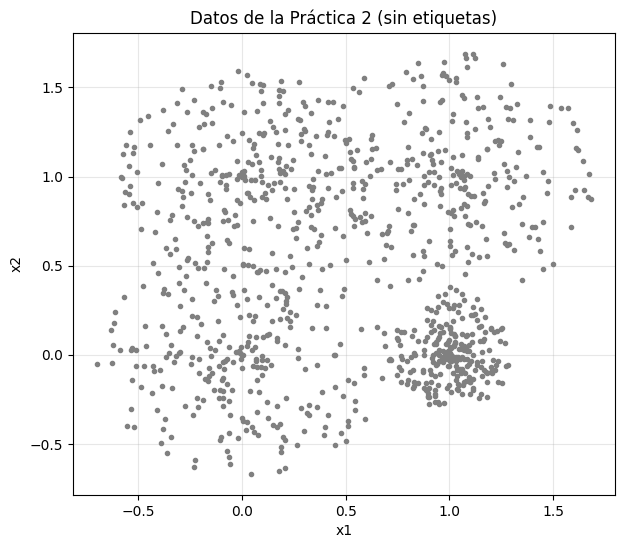

In [45]:
from minisom import MiniSom

# Cargar los datos (cada columna es un punto y cada fila una variable)
data2 = np.loadtxt("datos2.txt", delimiter=",")
if data2.shape[0] > data2.shape[1]:      # Si viene con un punto por fila, se transpone
    data2 = data2.T

X2 = data2.T                             # MiniSom trabaja con un punto por fila: (1000, 2)
print(f"Variables: {data2.shape[0]} | Puntos: {data2.shape[1]}")
print(f"Rango x1: [{data2[0].min():.2f}, {data2[0].max():.2f}] | Rango x2: [{data2[1].min():.2f}, {data2[1].max():.2f}]")

# Vista de los datos tal como llegan a la red (sin etiquetas)
plt.figure(figsize=(7, 6))
plt.plot(data2[0], data2[1], ".", color="gray")
plt.title("Datos de la Práctica 2 (sin etiquetas)")
plt.xlabel("x1"); plt.ylabel("x2"); plt.grid(alpha=0.3)
plt.show()

**b) Configuración y entrenamiento** (6 neuronas, σ = 0.01, α₀ = 0.5, 100 épocas)

El entrenamiento hace lo mismo que `red.train_random(X2, T)`: en cada iteración toma un dato al azar, busca la ganadora y llama a `red.update`. Se escribe el ciclo explícitamente solo para **guardar los pesos y el error al final de cada época** y poder graficar la convergencia.

In [46]:
nn2 = 6            # Número de neuronas (mapa de 6 x 1)
sigma2 = 0.01      # Vecindad casi nula: solo aprende la ganadora (red competitiva pura)
alpha2 = 0.5       # Tasa de aprendizaje inicial (decae durante el entrenamiento)
epocas2 = 100
T2 = epocas2 * X2.shape[0]   # Iteraciones totales: 100 épocas x 1000 datos

red = MiniSom(x=nn2, y=1, input_len=X2.shape[1], sigma=sigma2,
              learning_rate=alpha2, random_seed=42)   # Semilla fija para repetir resultados
red.random_weights_init(X2)                           # Pesos iniciales = puntos al azar de los datos
W2_0 = red.get_weights().reshape(nn2, -1).copy()      # Pesos iniciales (una fila por neurona)

rng2 = np.random.default_rng(42)
historial2 = [W2_0.copy()]       # Pesos al final de cada época
error_epoca = []                 # Error de cuantización al final de cada época
for t in range(T2):
    x = X2[rng2.integers(X2.shape[0])]          # Dato elegido al azar
    red.update(x, red.winner(x), t, T2)         # Competencia + actualización (alpha decae con t)
    if (t + 1) % X2.shape[0] == 0:              # Fin de una época
        historial2.append(red.get_weights().reshape(nn2, -1).copy())
        error_epoca.append(red.quantization_error(X2))
historial2 = np.array(historial2)               # (épocas + 1, neuronas, 2)

W2 = red.get_weights().reshape(nn2, -1)         # Pesos finales
grupos2 = np.array([red.winner(x)[0] for x in X2])   # Grupo de cada punto = neurona ganadora

print("Pesos iniciales (una fila por neurona):")
print(np.round(W2_0, 4))
print("\nPesos finales (una fila por neurona):")
print(np.round(W2, 4))

Pesos iniciales (una fila por neurona):
[[ 0.498   1.2054]
 [ 0.7669  1.044 ]
 [ 0.0077  0.6011]
 [ 0.0521  1.1616]
 [ 1.0153  0.8106]
 [ 0.7987 -0.143 ]]

Pesos finales (una fila por neurona):
[[-0.1565  0.3424]
 [-0.0502  1.2301]
 [ 1.1397  0.9633]
 [ 0.6278  1.0906]
 [ 1.0124  0.0364]
 [ 0.1345 -0.1768]]


<a id="p2-pruebas"></a>

### 3.4 Pruebas y resultados

**a) Movimiento de las neuronas, grupos encontrados y dato nuevo**

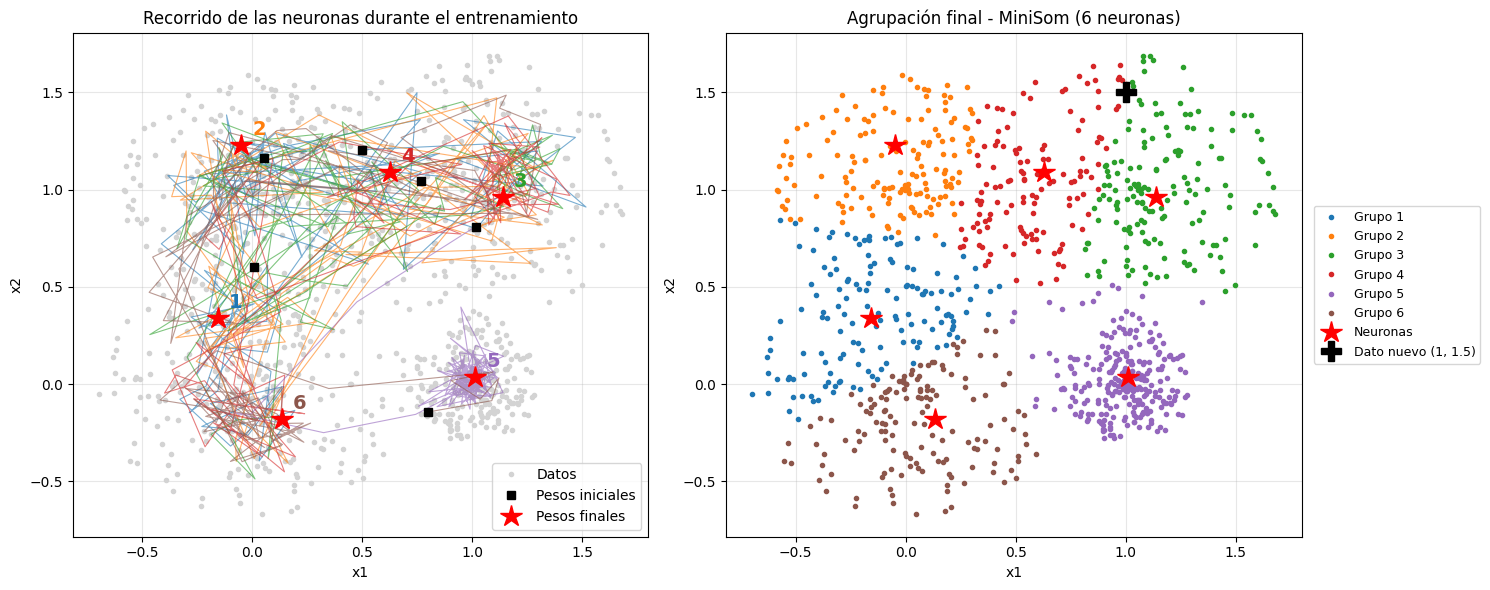

In [47]:
v = np.array([1.0, 1.5])            # Dato nuevo a clasificar
t_v = red.winner(v)[0]              # Neurona ganadora del dato nuevo

colores2 = plt.get_cmap("tab10").colors
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Izquierda: recorrido de cada neurona desde su posición inicial
axs[0].plot(data2[0], data2[1], ".", color="lightgray", label="Datos")
for j in range(nn2):
    axs[0].plot(historial2[:, j, 0], historial2[:, j, 1], "-", lw=0.8, alpha=0.6, color=colores2[j])
    axs[0].text(W2[j, 0] + 0.05, W2[j, 1] + 0.05, str(j + 1), fontsize=14, fontweight="bold", color=colores2[j])
axs[0].plot(W2_0[:, 0], W2_0[:, 1], "ks", ms=6, label="Pesos iniciales")
axs[0].plot(W2[:, 0], W2[:, 1], "r*", ms=16, label="Pesos finales")
axs[0].set(title="Recorrido de las neuronas durante el entrenamiento", xlabel="x1", ylabel="x2")
axs[0].legend(); axs[0].grid(alpha=0.3)

# Derecha: datos coloreados según su neurona ganadora y el dato nuevo
for j in range(nn2):
    axs[1].plot(data2[0, grupos2 == j], data2[1, grupos2 == j], ".", color=colores2[j], label=f"Grupo {j + 1}")
axs[1].plot(W2[:, 0], W2[:, 1], "r*", ms=16, label="Neuronas")
axs[1].plot(v[0], v[1], "kP", ms=14, label=f"Dato nuevo ({v[0]:g}, {v[1]:g})")
axs[1].set(title="Agrupación final - MiniSom (6 neuronas)", xlabel="x1", ylabel="x2")
axs[1].legend(fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5)); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**b) Convergencia:** error de cuantización y tasa de aprendizaje por época

El **error de cuantización** es la distancia promedio de cada punto a su neurona ganadora (`red.quantization_error`). Entre más bajo, mejor representan las neuronas a los datos.

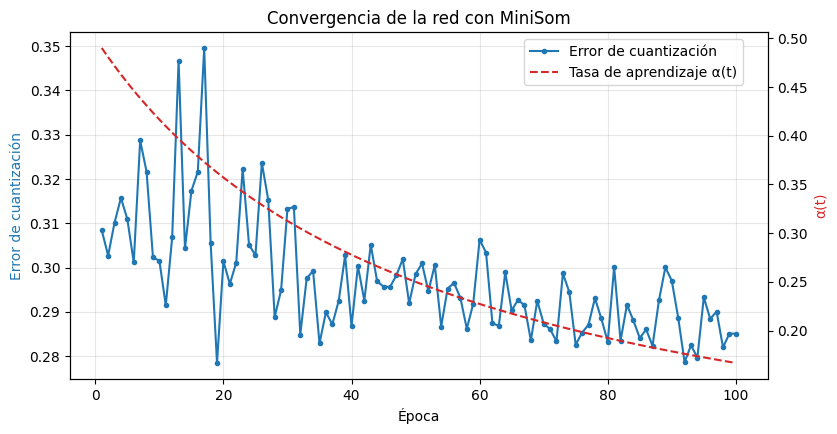

Error de cuantización: época 1 = 0.3084 | época 100 = 0.2851


,Neurona,Peso final x1,Peso final x2,Puntos asignados,Centro real x1,Centro real x2
0,1,-0.157,0.342,144,-0.156,0.361
1,2,-0.050,1.230,152,-0.060,1.138
2,3,1.140,0.963,161,1.177,1.005
3,4,0.628,1.091,132,0.588,1.049
4,5,1.012,0.036,264,0.991,0.022
5,6,0.135,-0.177,147,0.066,-0.203


In [48]:
ep = np.arange(1, epocas2 + 1)
alpha_t = alpha2 / (1 + 2 * (ep * X2.shape[0]) / T2)    # Tasa de aprendizaje al final de cada época

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(ep, error_epoca, "-o", ms=3, color="tab:blue", label="Error de cuantización")
ax1.set_xlabel("Época"); ax1.set_ylabel("Error de cuantización", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(ep, alpha_t, "--", color="tab:red", label="Tasa de aprendizaje α(t)")
ax2.set_ylabel("α(t)", color="tab:red")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
ax1.set_title("Convergencia de la red con MiniSom"); ax1.grid(alpha=0.3)
plt.show()

print(f"Error de cuantización: época 1 = {error_epoca[0]:.4f} | época {epocas2} = {error_epoca[-1]:.4f}")

# Resumen por grupo
resumen2 = pd.DataFrame({
    "Neurona": range(1, nn2 + 1),
    "Peso final x1": W2[:, 0].round(3),
    "Peso final x2": W2[:, 1].round(3),
    "Puntos asignados": [int((grupos2 == j).sum()) for j in range(nn2)],
    "Centro real x1": [data2[0, grupos2 == j].mean().round(3) for j in range(nn2)],
    "Centro real x2": [data2[1, grupos2 == j].mean().round(3) for j in range(nn2)]})
resumen2

**c) Clasificación del dato nuevo $(1, 1.5)$**

In [49]:
distancias_v = np.linalg.norm(W2 - v, axis=1)   # Distancia del dato nuevo a cada neurona

# Vector de salida one-hot: 1 en la neurona ganadora
salida2 = np.zeros((nn2, 1))
salida2[t_v, 0] = 1

print(f"Distancias del dato {v} a cada neurona: {np.round(distancias_v, 4)}")
print(f"Neurona ganadora: {t_v + 1}  (peso = ({W2[t_v, 0]:.2f}, {W2[t_v, 1]:.2f}))")
print("Salida de la red (one-hot):")
print(salida2)

Distancias del dato [1.  1.5] a cada neurona: [1.6363 1.0843 0.5546 0.5534 1.4637 1.887 ]
Neurona ganadora: 4  (peso = (0.63, 1.09))
Salida de la red (one-hot):
[[0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]]


**d) Pruebas con distinto número de neuronas**

Se entrena la red con 2 a 10 neuronas (misma configuración y semilla, usando directamente `train_random`). Para cada caso se mide el error de cuantización y las neuronas muertas. Además se grafica la agrupación con 4 y 8 neuronas para compararla con la de 6.

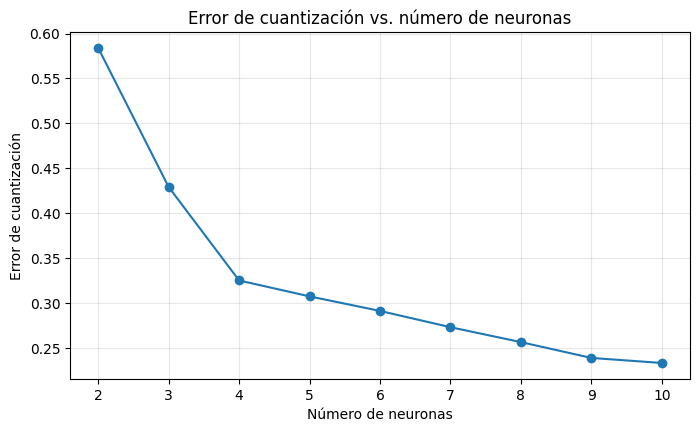

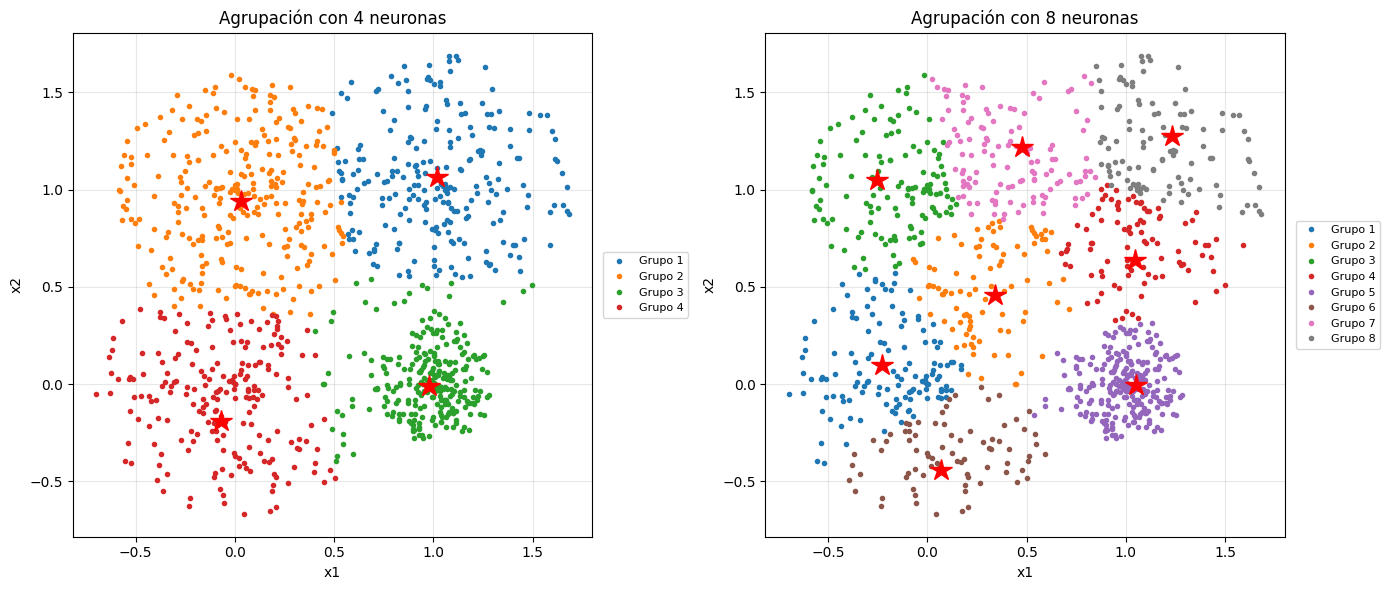

,Error de cuantización,Neuronas muertas,Puntos por neurona
Neuronas,,,
2,0.5839,0,"[490, 510]"
3,0.4292,0,"[230, 426, 344]"
4,0.3252,0,"[234, 275, 281, 210]"
5,0.3075,0,"[172, 278, 163, 220, 167]"
6,0.2913,0,"[120, 188, 179, 261, 126, 126]"
7,0.2732,0,"[116, 138, 82, 171, 137, 261, 95]"
8,0.2566,0,"[131, 92, 130, 92, 248, 79, 121, 107]"
9,0.2390,0,"[111, 84, 83, 98, 64, 76, 249, 114, 121]"
10,0.2334,0,"[79, 80, 65, 83, 66, 252, 109, 78, 53, 135]"


In [50]:
def entrenar_minisom(nn_c, sigma_c=0.01, alpha_c=0.5, epocas_c=100, semilla=42):
    # Entrena un MiniSom de nn_c x 1 y regresa la red, los pesos finales y el grupo de cada punto
    r = MiniSom(x=nn_c, y=1, input_len=X2.shape[1], sigma=sigma_c, learning_rate=alpha_c, random_seed=semilla)
    r.random_weights_init(X2)
    r.train_random(X2, num_iteration=epocas_c * X2.shape[0])
    g = np.array([r.winner(x)[0] for x in X2])
    return r, r.get_weights().reshape(nn_c, -1), g

filas = []
for n_c in range(2, 11):
    r_c, W_c, g_c = entrenar_minisom(n_c)
    filas.append({"Neuronas": n_c,
                  "Error de cuantización": round(r_c.quantization_error(X2), 4),
                  "Neuronas muertas": int(sum((g_c == j).sum() == 0 for j in range(n_c))),
                  "Puntos por neurona": np.bincount(g_c, minlength=n_c).tolist()})
tabla_nn = pd.DataFrame(filas).set_index("Neuronas")

# Curva del error contra el número de neuronas
plt.figure(figsize=(8, 4.5))
plt.plot(tabla_nn.index, tabla_nn["Error de cuantización"], "-o")
plt.xlabel("Número de neuronas"); plt.ylabel("Error de cuantización")
plt.title("Error de cuantización vs. número de neuronas"); plt.grid(alpha=0.3)
plt.show()

# Agrupación con 4 y 8 neuronas
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax, n_c in zip(axs, [4, 8]):
    _, W_c, g_c = entrenar_minisom(n_c)
    for j in range(n_c):
        ax.plot(data2[0, g_c == j], data2[1, g_c == j], ".", color=colores2[j], label=f"Grupo {j + 1}")
    ax.plot(W_c[:, 0], W_c[:, 1], "r*", ms=16)
    ax.set(title=f"Agrupación con {n_c} neuronas", xlabel="x1", ylabel="x2")
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

tabla_nn

**e) Efecto del tamaño de la vecindad σ** (6 neuronas)

Con σ grande, MiniSom deja de ser una red competitiva pura: las vecinas de la ganadora también se mueven hacia el dato y las neuronas se "jalan" entre sí.

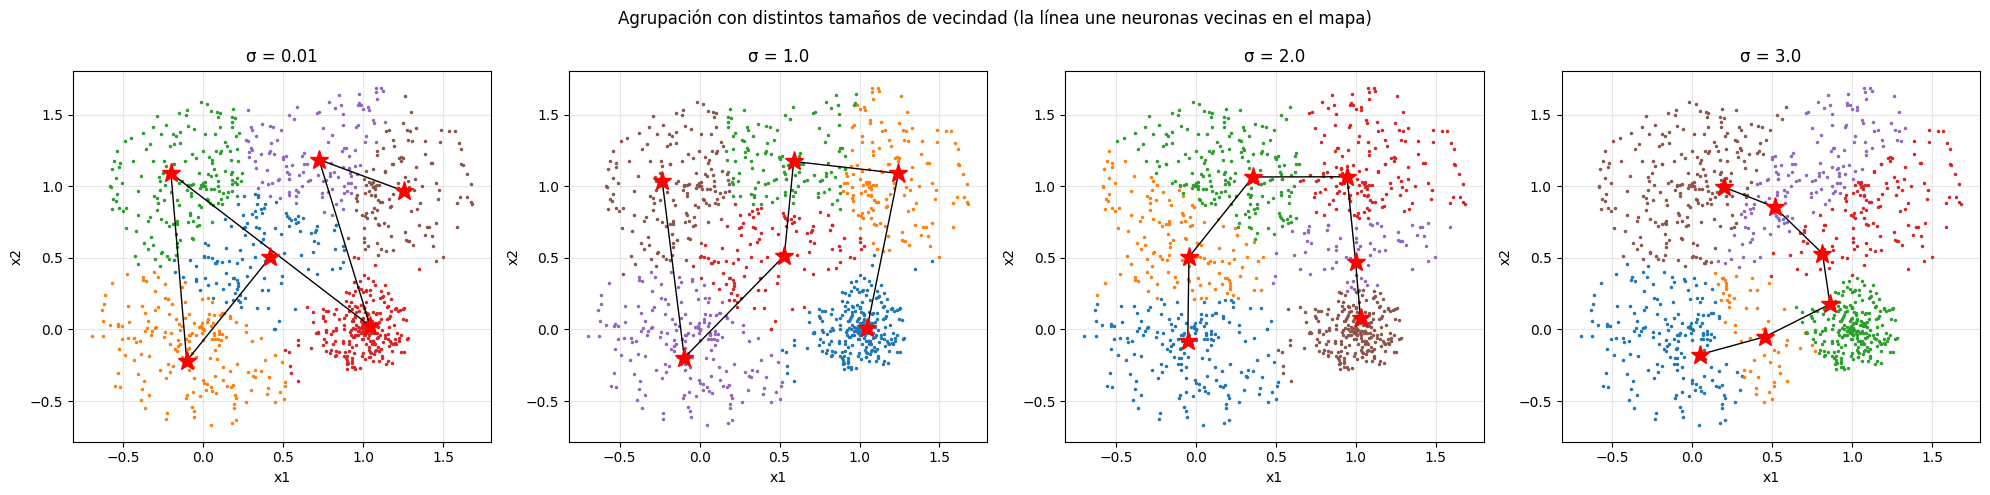

,Error de cuantización,Puntos por neurona
sigma,,
0.01,0.2913,"[120, 188, 179, 261, 126, 126]"
1.00,0.2922,"[260, 147, 121, 111, 195, 166]"
2.00,0.2988,"[183, 142, 194, 165, 69, 247]"
3.00,0.3833,"[182, 56, 245, 136, 151, 230]"


In [51]:
sigmas = [0.01, 1.0, 2.0, 3.0]
fig, axs = plt.subplots(1, len(sigmas), figsize=(20, 5))
filas_s = []
for ax, s in zip(axs, sigmas):
    r_s, W_s, g_s = entrenar_minisom(nn2, sigma_c=s)
    filas_s.append({"sigma": s, "Error de cuantización": round(r_s.quantization_error(X2), 4),
                    "Puntos por neurona": np.bincount(g_s, minlength=nn2).tolist()})
    for j in range(nn2):
        ax.plot(data2[0, g_s == j], data2[1, g_s == j], ".", ms=3, color=colores2[j])
    ax.plot(W_s[:, 0], W_s[:, 1], "k-", lw=1)            # Línea que une neuronas vecinas en el mapa
    ax.plot(W_s[:, 0], W_s[:, 1], "r*", ms=14)
    ax.set(title=f"σ = {s}", xlabel="x1", ylabel="x2"); ax.grid(alpha=0.3)
plt.suptitle("Agrupación con distintos tamaños de vecindad (la línea une neuronas vecinas en el mapa)")
plt.tight_layout(); plt.show()

tabla_sigma = pd.DataFrame(filas_s).set_index("sigma")
tabla_sigma

In [52]:
# Resumen de resultados en palabras
print("RESUMEN DE LA PRÁCTICA 2")
dist_centro2 = np.linalg.norm(W2 - resumen2[["Centro real x1", "Centro real x2"]].values, axis=1)
print(f"- Cada neurona quedó a {dist_centro2.min():.3f}-{dist_centro2.max():.3f} unidades del centro de su grupo.")
print(f"- Puntos por grupo: {resumen2['Puntos asignados'].tolist()}.")
print(f"- El error de cuantización bajó de {error_epoca[0]:.4f} (época 1) a {error_epoca[-1]:.4f} (época {epocas2}).")
print(f"- El dato nuevo {v} quedó en el grupo de la neurona {t_v + 1}, cuyo peso es ({W2[t_v, 0]:.2f}, {W2[t_v, 1]:.2f}).")
print(f"- Neuronas muertas en las pruebas de 2 a 10 neuronas: {int(tabla_nn['Neuronas muertas'].sum())}.")
print(f"- Error con sigma = {sigmas[0]}: {tabla_sigma.iloc[0, 0]} | con sigma = {sigmas[-1]}: {tabla_sigma.iloc[-1, 0]}.")

RESUMEN DE LA PRÁCTICA 2
- Cada neurona quedó a 0.019-0.093 unidades del centro de su grupo.
- Puntos por grupo: [144, 152, 161, 132, 264, 147].
- El error de cuantización bajó de 0.3084 (época 1) a 0.2851 (época 100).
- El dato nuevo [1.  1.5] quedó en el grupo de la neurona 4, cuyo peso es (0.63, 1.09).
- Neuronas muertas en las pruebas de 2 a 10 neuronas: 0.
- Error con sigma = 0.01: 0.2913 | con sigma = 3.0: 0.3833.


**Análisis**
- **Agrupación:** con 6 neuronas, cada peso final quedó prácticamente en el centro de su grupo (a menos de 0.1 unidades del promedio de sus puntos, tabla del inciso b). La **nube densa de abajo a la derecha** se quedó con **una sola neurona** (neurona 5, ≈ 264 puntos) porque sus puntos están muy juntos y un solo prototipo los representa bien. Las otras 5 neuronas se repartieron la zona dispersa: como ahí los puntos están más separados, la red "parte" esas nubes en varios pedazos para que ningún punto quede lejos de su neurona.
- **Recorrido de las neuronas:** a diferencia de la Práctica 1, los pesos iniciales son puntos de los mismos datos, así que todas las neuronas empiezan dentro de la nube y **ninguna quedó muerta**. Los recorridos se ven en zigzag porque α₀ = 0.5 es grande: la ganadora avanza la mitad de la distancia hacia cada dato, así que "brinca" según el último dato que le tocó. La neurona de la nube densa se mueve mucho menos porque todos sus datos están cerca.
- **Convergencia:** el error de cuantización baja de ≈ 0.31 a ≈ 0.285 y las oscilaciones se hacen más chicas conforme α(t) disminuye. El error de la primera época ya es bajo porque las neuronas empiezan sobre los datos. Como α(t) solo baja hasta ≈ 0.17 y nunca llega a cero, los pesos siguen vibrando un poco al final; con una tasa que termine más cerca de cero los pesos se quedarían quietos.
- **Dato nuevo (1, 1.5):** la red activa una sola neurona (salida one-hot), la **neurona 4**. Sin embargo, la distancia a la neurona 4 (0.5534) y a la neurona 3 (0.5546) es casi igual: el punto está arriba de la frontera entre esos dos grupos, los dos en la nube de arriba a la derecha. Por eso, si se cambia la semilla, el dato puede caer en cualquiera de los dos grupos (en el código de clase, sin semilla, salió en otro grupo). En los dos casos la red lo ubica en la nube de arriba a la derecha, que es la más cercana.
- **Número de neuronas:** el error baja mucho de 2 a 4 neuronas (0.58 → 0.43 → 0.33) y después baja poco (0.31, 0.29, 0.27…). Ese "codo" en 4 indica que los datos tienen **4 grupos naturales**, con centros cerca de (0, 0), (0, 1), (1, 0) y (1, 1), y con 4 neuronas cada una se queda con ≈ 210–280 puntos. Agregar más neuronas siempre baja el error, pero ya no encuentra grupos nuevos, solo divide los que existen. En ninguno de los casos hubo neuronas muertas gracias a la inicialización con datos.
- **Tamaño de la vecindad σ:** con σ = 0.01 la red es competitiva pura. Con σ = 1 el resultado casi no cambia (error 0.2922 contra 0.2913). Con σ = 2 y σ = 3, las vecinas de la ganadora también se mueven, las neuronas se jalan entre sí y forman una cadena ordenada (la línea negra), pero se alejan de los centros de los grupos y el error sube hasta 0.3833. Para agrupar conviene σ pequeña. Una σ grande sirve cuando lo que importa es conservar el orden entre neuronas (mapa autoorganizado), no la precisión de cada grupo.
- **Comparación con la Práctica 1:** MiniSom hace el mismo trabajo que el código hecho a mano, pero con menos líneas y con mejoras ya incluidas: inicialización con los datos, tasa de aprendizaje que decae y vecindad configurable.

<a id="practica3"></a>

## 4. Práctica 3: red competitiva para agrupar activos de la BMV

### Introduccion 
Una red neuronal competitiva aprende sin supervisión: las neuronas "compiten" por cada dato y solo la que más se le parece (la ganadora) ajusta sus pesos hacia él. Al final, cada neurona queda como el prototipo (centroide) de un grupo de datos parecidos.

Aquí la usé para agrupar 35 activos de la BMV según cómo se comportan en el tiempo. Como sus precios están en escalas muy distintas, primero los normalicé con Z-score para comparar la forma de cada serie y no su tamaño.

Objetivo: separar los 35 activos en 4 grupos de comportamiento parecido, usando una red competitiva con MiniSom, y analizar qué tiene cada grupo.

Agrupamiento Competitivo de los 35 Activos de la BMV:

Activo BMV_01: Pertenece a la Neurona Ganadora 1
Activo BMV_02: Pertenece a la Neurona Ganadora 1
Activo BMV_03: Pertenece a la Neurona Ganadora 1
Activo BMV_04: Pertenece a la Neurona Ganadora 1
Activo BMV_05: Pertenece a la Neurona Ganadora 3
Activo BMV_06: Pertenece a la Neurona Ganadora 1
Activo BMV_07: Pertenece a la Neurona Ganadora 3
Activo BMV_08: Pertenece a la Neurona Ganadora 3
Activo BMV_09: Pertenece a la Neurona Ganadora 3
Activo BMV_10: Pertenece a la Neurona Ganadora 1
Activo BMV_11: Pertenece a la Neurona Ganadora 3
Activo BMV_12: Pertenece a la Neurona Ganadora 4
Activo BMV_13: Pertenece a la Neurona Ganadora 1
Activo BMV_14: Pertenece a la Neurona Ganadora 4
Activo BMV_15: Pertenece a la Neurona Ganadora 2
Activo BMV_16: Pertenece a la Neurona Ganadora 1
Activo BMV_17: Pertenece a la Neurona Ganadora 1
Activo BMV_18: Pertenece a la Neurona Ganadora 3
Activo BMV_19: Pertenece a la Neurona Ganadora 1
Activo BMV_20:

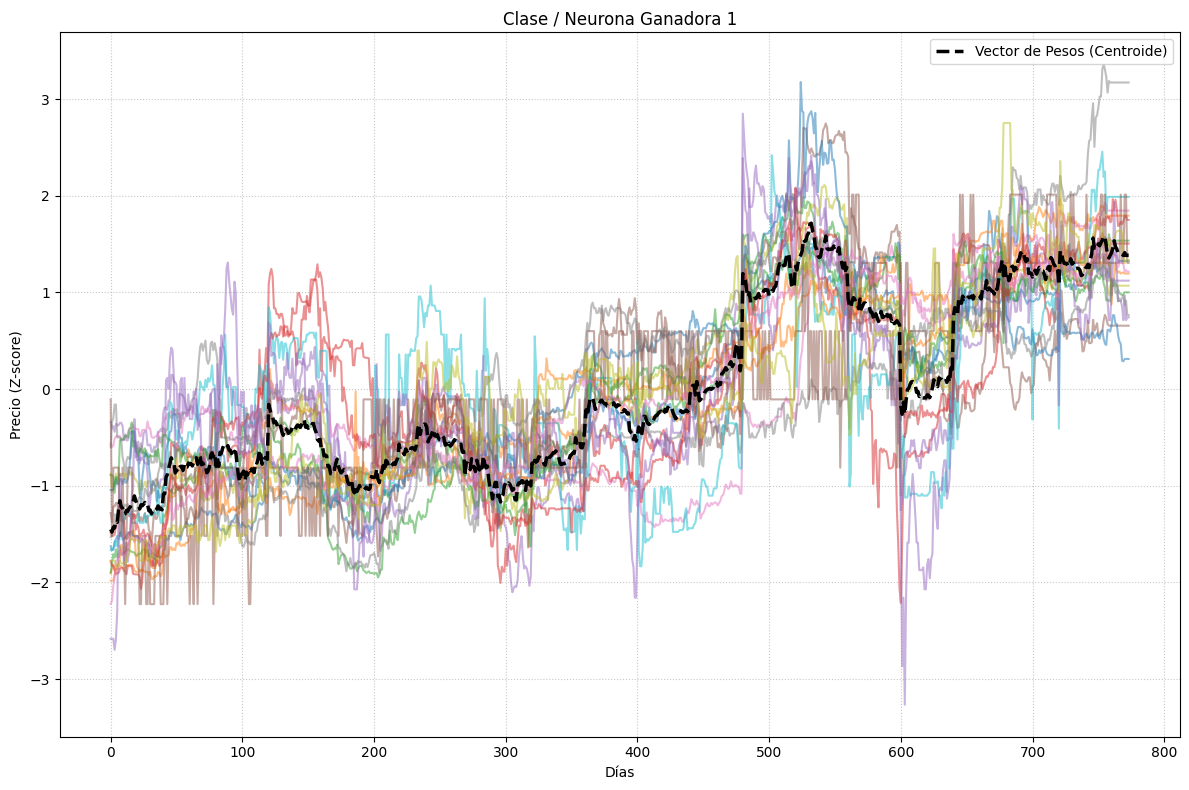

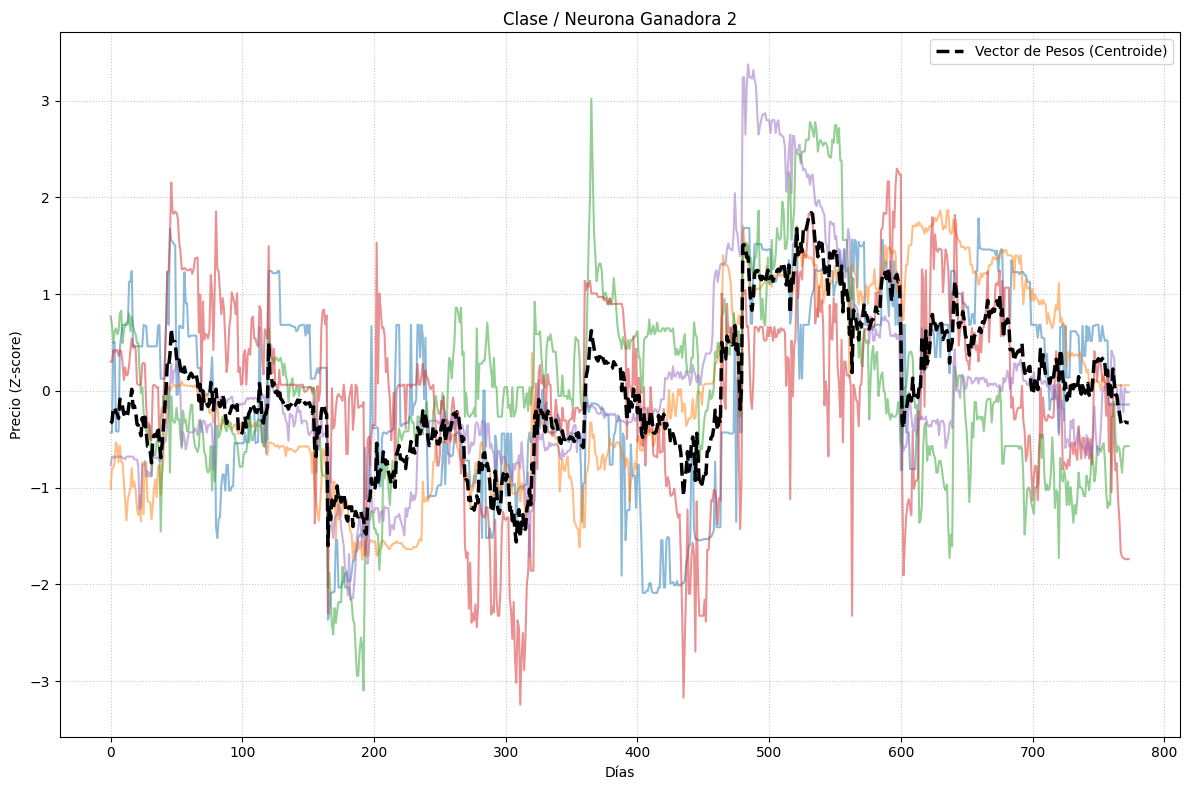

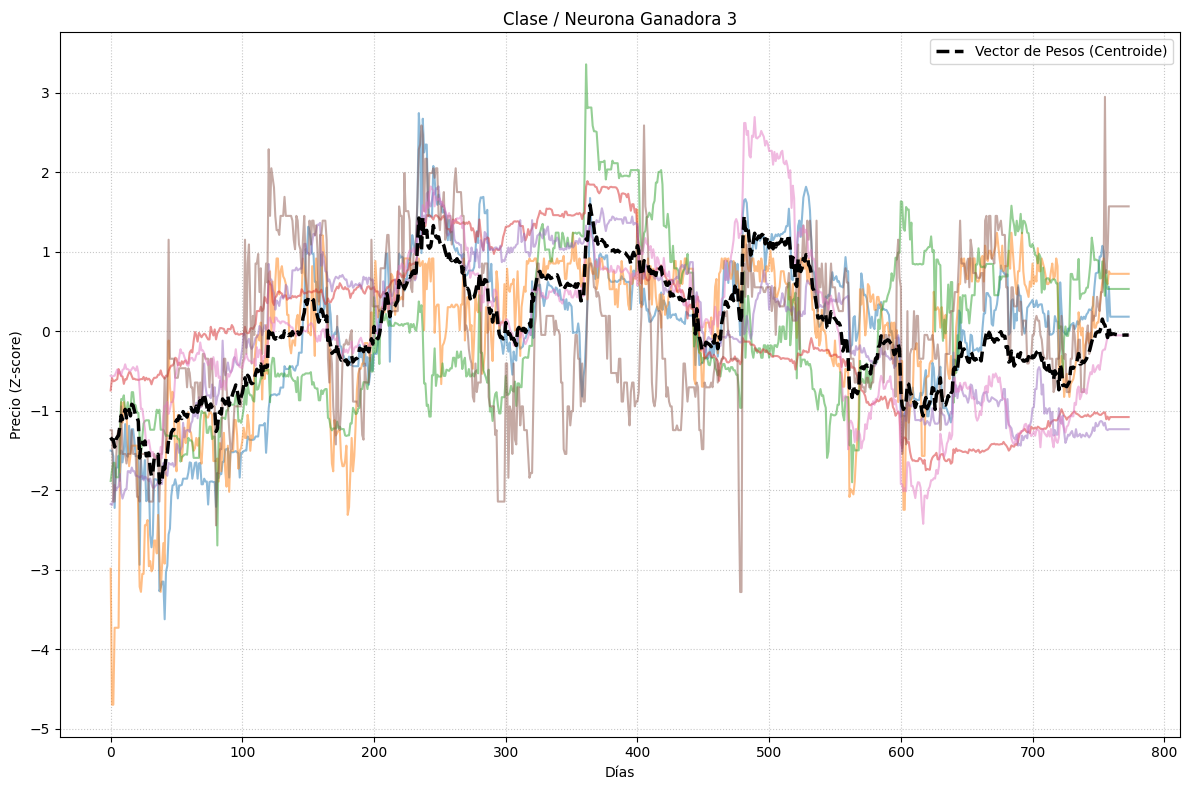

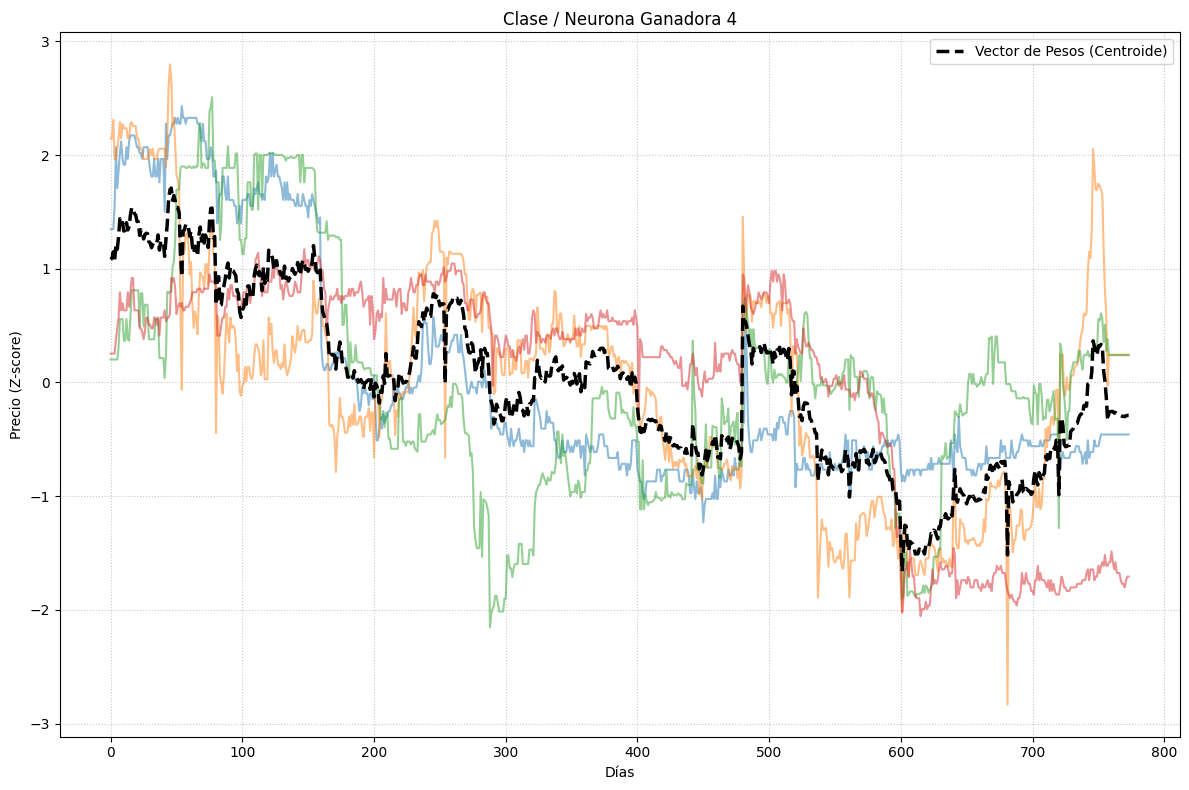

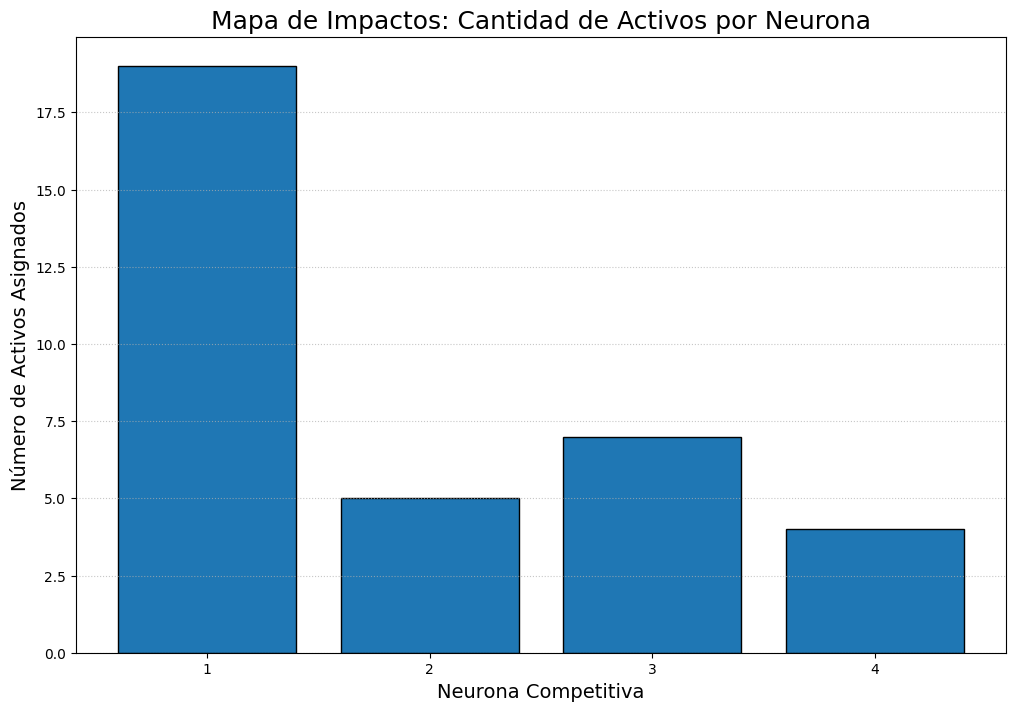

In [53]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from minisom import MiniSom
import matplotlib.pyplot as plt

# 1. Cargar los datos
df = pd.read_csv('Datos_BMV.csv', header=None)
data = df.values 

# Normalizar los datos por columna usando Z-score
data_norm = zscore(data, axis=0)

# 2. Preparar los datos para la red
# Cada fila representa un activo y cada columna un día
X_train = data_norm.T  
num_activos, num_dias = X_train.shape

# 3. Configurar la red neuronal
# Se utilizan 4 neuronas competitivas
num_neuronas = 4  
som = MiniSom(x=num_neuronas, y=1, input_len=num_dias, sigma=1.0, learning_rate=0.5, random_seed=42)

# Inicializar los pesos de las neuronas
som.random_weights_init(X_train)

# 4. Entrenar la red neuronal
num_iteraciones = 1000  
som.train_random(data=X_train, num_iteration=num_iteraciones)

# 5. Clasificar los activos
print("Agrupamiento Competitivo de los 35 Activos de la BMV:\n")
etiquetas_clases = []

# Identificar la neurona ganadora de cada activo
for i, x in enumerate(X_train):
    neurona_ganadora = som.winner(x)[0] 
    clase_asignada = neurona_ganadora + 1 
    etiquetas_clases.append(clase_asignada)
    print(f"Activo BMV_{i+1:02d}: Pertenece a la Neurona Ganadora {clase_asignada}")

# 6. Gráfica 1: Comportamiento de los activos por grupo

# Obtener los pesos finales de las neuronas
pesos_red = som.get_weights()[:, 0, :]

# Crear una gráfica para cada neurona
for i in range(num_neuronas):
    plt.figure(figsize=(12,8))
    plt.title(f'Clase / Neurona Ganadora {i + 1}',fontsize=12)

    # Seleccionar los activos que pertenecen a cada grupo
    activos_clase = [idx for idx, clase in enumerate(etiquetas_clases) if clase == i + 1]

    # Graficar los activos del grupo
    for idx in activos_clase:
        plt.plot(X_train[idx], alpha=0.5)

    # Agregar los pesos de la neurona como referencia
    plt.plot(pesos_red[i], color='black', linewidth=2.5, linestyle='--', label='Vector de Pesos (Centroide)')

    plt.ylabel('Precio (Z-score)')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='upper right')
    plt.xlabel('Días')
    plt.tight_layout()
    plt.show()

# 7. Gráfica 2: Cantidad de activos por neurona

# Contar cuántos activos quedaron en cada grupo
frecuencias = [etiquetas_clases.count(i) for i in range(1, num_neuronas + 1)]

# Graficar la cantidad de activos por neurona
plt.figure(figsize=(12, 8))
plt.bar(range(1, num_neuronas + 1), frecuencias, color='#1f77b4', edgecolor='black')
plt.title('Mapa de Impactos: Cantidad de Activos por Neurona', fontsize=18)
plt.xlabel('Neurona Competitiva', fontsize=14)
plt.ylabel('Número de Activos Asignados', fontsize=14)
plt.xticks(range(1, num_neuronas + 1))
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

## Resultados 
Clasificación: Los 35 activos se distribuyeron en 4 neuronas: 19 en la neurona 1, 5 en la 2, 7 en la 3 y 4 en la 4.

Gráficas por clase: Las líneas de colores representan los activos y la línea negra punteada el centroide de cada grupo.
- Neurona 1: Comportamiento principalmente alcista y el grupo más compacto.
- Neurona 2: Comportamiento lateral, con bastante volatilidad.
- Neurona 3: Presenta una tendencia alcista inicial y después se estabiliza.
- Neurona 4: Comportamiento bajista, contrario a la neurona 1.
Mapa de impactos: La neurona 1 concentra más de la mitad de los activos (19), seguida de la 3 (7), la 2 (5) y la 4 (4). Esto muestra que el comportamiento más frecuente fue el alcista, mientras que el bajista fue el menos común.



<a id="practica4"></a>

## 5. Práctica 4: patrones en una serie de tiempo del activo BMV_24

<a id="p4-definicion"></a>

### 5.1 Definición del problema

En la Práctica 3 la red agrupó **activos completos** (cada activo era un dato). Aquí se agrupan **pedazos de la serie de un solo activo**: el archivo `Datos_BMV.csv` guarda los precios diarios de 35 activos y se toma la columna 24 (`BMV_24`, índice 23 en Python). Los precios no traen ninguna etiqueta que diga "este tramo fue alcista" o "este fue lateral", así que es un problema **no supervisado**.

Se busca:

1. Cortar la serie en **ventanas deslizantes de 35 días** (una ventana nueva por cada día que avanza).
2. **Normalizar cada ventana** con z-score para comparar la *forma* del movimiento y no el nivel del precio.
3. Entrenar una red competitiva de **5 neuronas** para que cada neurona quede como el **patrón típico** de un grupo de ventanas.
4. Asignar cada ventana a su neurona ganadora y ver **cómo cambia la clase a lo largo del tiempo** frente a la serie original.
5. Revisar qué tan confiable es el resultado al cambiar el número de neuronas, la semilla y la vecindad $\sigma$.

<a id="p4-algoritmo"></a>

### 5.2 Descripción del algoritmo

1. **Carga:** se lee `Datos_BMV.csv` y se extrae la serie `temp` del activo BMV_24 (longitud $T$).
2. **Ventanas deslizantes:** la ventana $k$ contiene los días $k,\dots,k+34$. Hay $T-35+1$ ventanas posibles. Cada ventana es una fila de la matriz de entrenamiento (muestras × 35).
3. **Limpieza:** si una ventana es constante, su desviación estándar es 0 y el z-score se indefine (NaN), por lo que se descarta.
4. **Normalización:** cada ventana se estandariza por separado: $\tilde{x}=(x-\mu_{ventana})/\sigma_{ventana}$. Así dos ventanas con la misma forma quedan iguales aunque el precio sea distinto.
5. **Red competitiva:** MiniSom de $5\times 1$ neuronas con $\sigma=0.01$ (vecindad casi nula, igual que en la Práctica 2), pesos iniciales tomados de las mismas ventanas y regla de Kohonen sobre la ganadora:
$$w_g \leftarrow w_g + \alpha(t)\,(\tilde{x}-w_g)$$
6. **Clasificación:** cada ventana pertenece a la neurona más cercana (regla del ganador). Los pesos finales `Wf` son el patrón representativo de cada clase.
7. **Interpretación temporal:** la clase de la ventana $k$ se coloca en el día en que **termina** la ventana ($k+34$), para compararla con la serie original.

**Pseudocódigo**
```
INICIO
    temp <- columna 24 de Datos_BMV.csv
    PARA k = 0 HASTA T-35 HACER  X[k] <- temp[k : k+35]
    Quitar ventanas con desviación estándar = 0
    X <- z-score de cada fila
    Inicializar 5 neuronas con ventanas al azar
    Entrenar (regla del ganador) durante N iteraciones
    PARA cada ventana x HACER  clase[x] <- neurona más cercana
    Graficar ventanas de cada clase, patrones Wf y clase vs. tiempo
FIN
```

<a id="p4-implementacion"></a>

### 5.3 Implementación

**a) Carga de datos y ventanas deslizantes**

In [54]:
%pip install minisom

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from minisom import MiniSom
import matplotlib.pyplot as plt

# 1. Carga de datos y selección del activo (BMV_24 = columna 24, índice 23)
df4 = pd.read_csv('Datos_BMV.csv', header=None)
temp = df4.iloc[:, 23].values.astype(float)

# 2. Ventanas deslizantes: cada ventana es una fila (muestras x 35)
ventana = 35
num_ventanas = len(temp) - ventana + 1          # +1 para incluir la última ventana posible
X_win = np.array([temp[k : k + ventana] for k in range(num_ventanas)])

# 3. Se descartan ventanas constantes (desviación 0 -> el z-score daría NaN)
validas = X_win.std(axis=1) > 0
X_win = X_win[validas]
dia_fin = np.arange(num_ventanas)[validas] + ventana - 1   # día en que termina cada ventana

# 4. Normalización z-score de cada ventana por separado (por fila)
X_train_norm = zscore(X_win, axis=1)

print(f"Días en la serie: {len(temp)} | Ventanas posibles: {num_ventanas} | "
      f"Ventanas usadas: {X_train_norm.shape[0]} | Descartadas: {num_ventanas - X_train_norm.shape[0]}")
print(f"Dimensión de la matriz de entrenamiento: {X_train_norm.shape}")



Días en la serie: 774 | Ventanas posibles: 740 | Ventanas usadas: 740 | Descartadas: 0
Dimensión de la matriz de entrenamiento: (740, 35)


**b) Funciones de la red y entrenamiento** (5 neuronas, σ = 0.01, α₀ = 0.5, 50 épocas)

In [56]:
def entrenar_som(nn_c, sigma_c=0.01, alpha_c=0.5, epocas_c=50, semilla=42):
    # Entrena un MiniSom de nn_c x 1 y regresa la red y la clase (0..nn_c-1) de cada ventana
    r = MiniSom(x=nn_c, y=1, input_len=ventana, sigma=sigma_c,
                learning_rate=alpha_c, random_seed=semilla)
    r.random_weights_init(X_train_norm)          # Pesos iniciales = ventanas reales
    r.train_random(X_train_norm, num_iteration=epocas_c * X_train_norm.shape[0])
    g = np.array([r.winner(x)[0] for x in X_train_norm])
    return r, g

num_neuronas = 5
som, g_idx = entrenar_som(num_neuronas)
Wf = som.get_weights()[:, 0, :]                  # Pesos finales: un patrón por neurona (5 x 35)
etiquetas_clases = g_idx + 1                      # Clases 1..5

grupos = np.unique(etiquetas_clases)
print(f"Grupos únicos identificados por la red: {grupos}")
print(f"Ventanas por grupo: {np.bincount(g_idx, minlength=num_neuronas).tolist()}")

Grupos únicos identificados por la red: [1 2 3 4 5]
Ventanas por grupo: [182, 100, 125, 255, 78]


<a id="p4-pruebas"></a>

### 5.4 Pruebas y resultados

**a) Ventanas de cada grupo y su patrón (pesos finales)**

Cada gráfica superpone todas las ventanas que ganó una neurona; la línea negra punteada es el vector de pesos `Wf` de esa neurona.

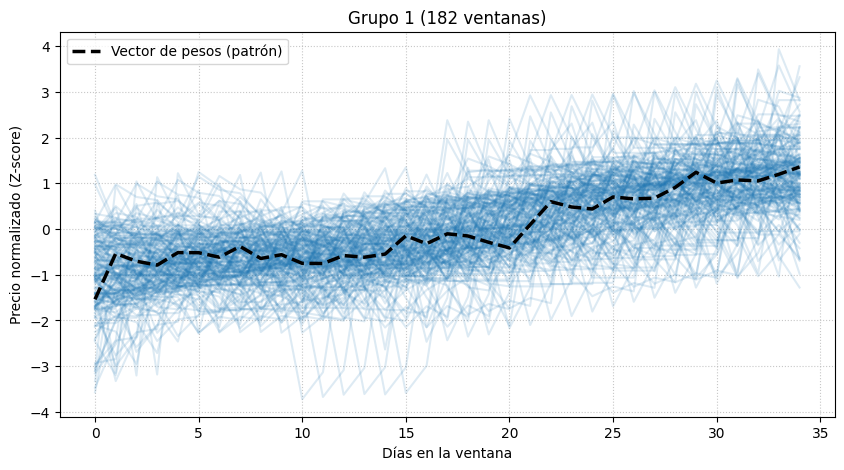

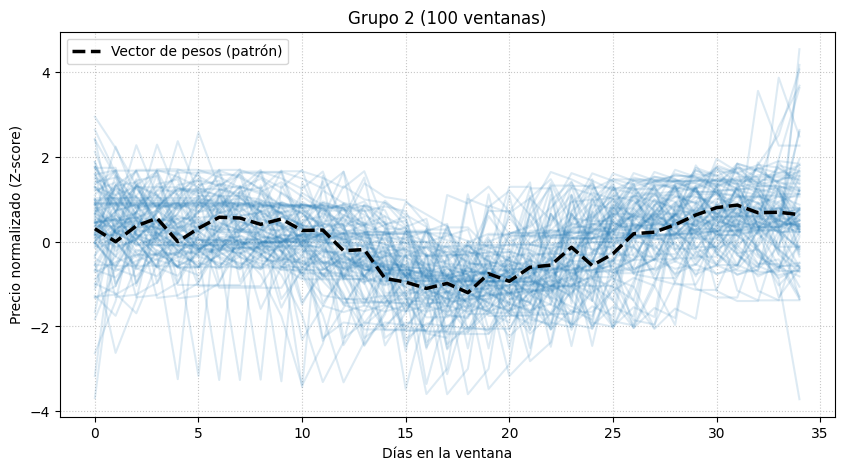

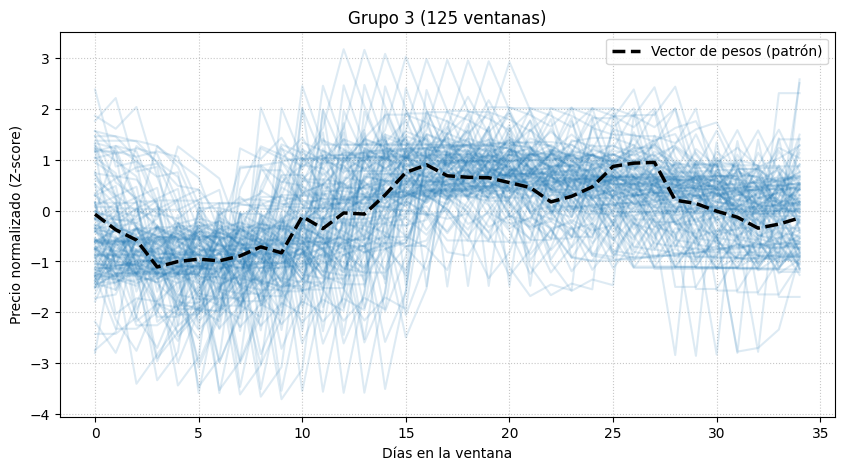

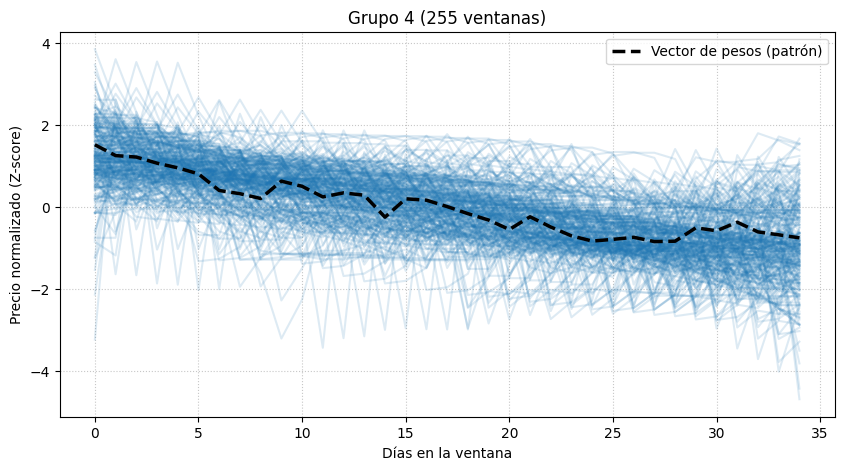

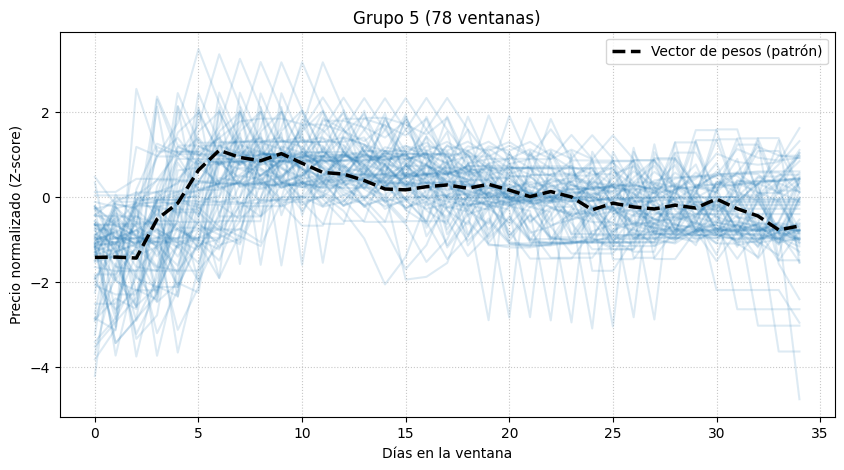

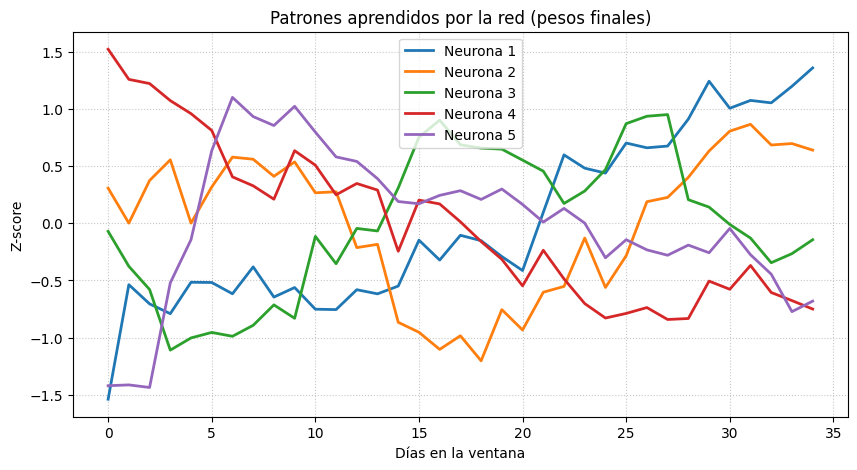

In [57]:
for k in range(num_neuronas):
    plt.figure(figsize=(10, 5))
    grupo_k = X_train_norm[g_idx == k]
    for w in grupo_k:
        plt.plot(w, alpha=0.15, color='tab:blue')
    plt.plot(Wf[k], 'k--', lw=2.5, label='Vector de pesos (patrón)')
    plt.title(f'Grupo {k + 1} ({len(grupo_k)} ventanas)')
    plt.xlabel('Días en la ventana'); plt.ylabel('Precio normalizado (Z-score)')
    plt.grid(True, linestyle=':', alpha=0.7); plt.legend()
    plt.show()

# Los 5 patrones juntos para compararlos
plt.figure(figsize=(10, 5))
for k in range(num_neuronas):
    plt.plot(Wf[k], lw=2, label=f'Neurona {k + 1}')
plt.title('Patrones aprendidos por la red (pesos finales)')
plt.xlabel('Días en la ventana'); plt.ylabel('Z-score')
plt.grid(True, linestyle=':', alpha=0.7); plt.legend()
plt.show()

**b) Serie original contra la clase asignada en el tiempo**

La barra de cada día es la clase de la ventana que **termina** ese día.

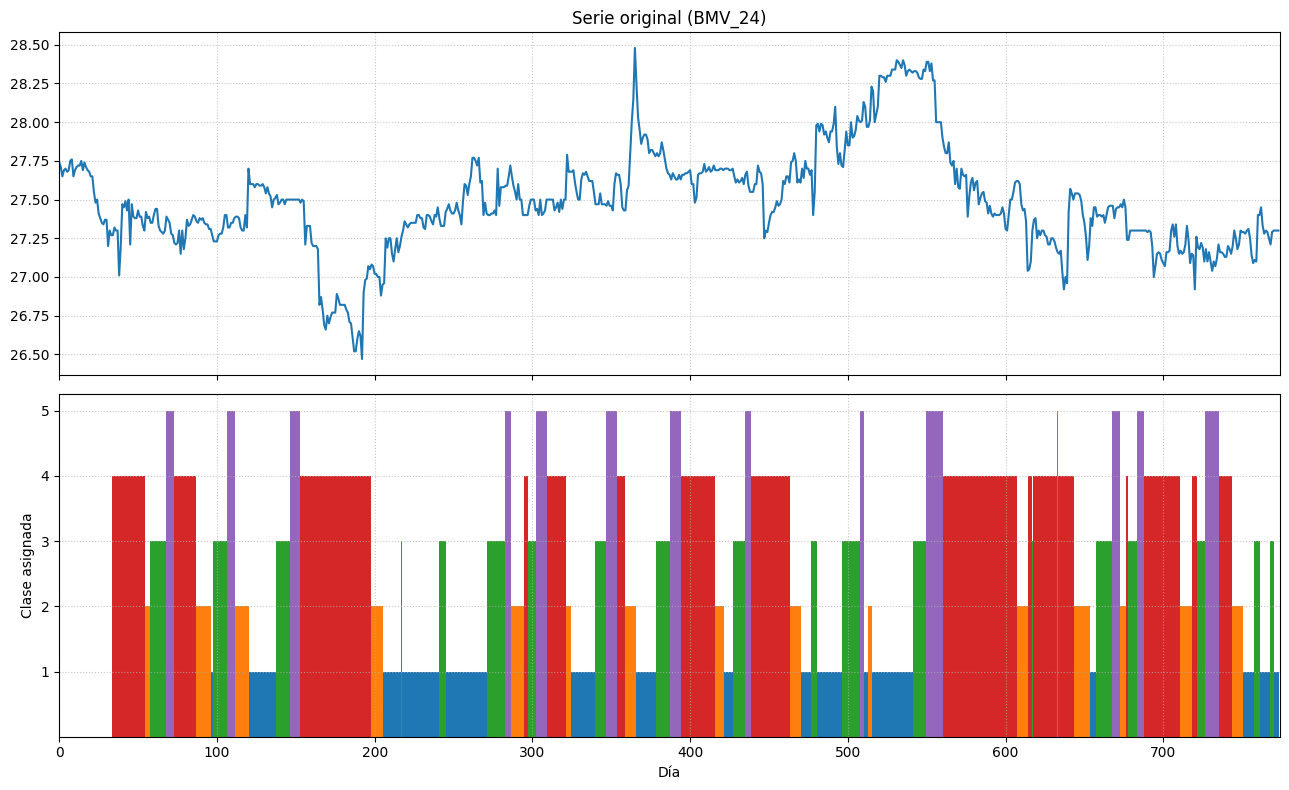

In [58]:
colores4 = plt.get_cmap("tab10").colors
fig, axs = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axs[0].plot(temp, color='#1f77b4')
axs[0].set_title('Serie original (BMV_24)'); axs[0].grid(True, linestyle=':', alpha=0.7)

axs[1].bar(dia_fin, etiquetas_clases, width=1.0,
           color=[colores4[c] for c in g_idx])
axs[1].set_ylabel('Clase asignada'); axs[1].set_xlabel('Día')
axs[1].set_yticks(range(1, num_neuronas + 1)); axs[1].set_xlim(0, len(temp))
axs[1].grid(True, linestyle=':', alpha=0.7)
plt.tight_layout(); plt.show()

**c) Cuántas ventanas cae en cada grupo y qué tan estable es la clase en el tiempo**

Como dos ventanas consecutivas comparten 34 de sus 35 días, es normal que la clase se mantenga varios días seguidos. Se mide cuántas veces cambia de clase y cuánto dura cada tramo.

In [59]:
cuentas = np.bincount(g_idx, minlength=num_neuronas)
# Tramos: días consecutivos con la misma clase (solo se comparan ventanas contiguas en el tiempo)
contiguas = np.diff(dia_fin) == 1
cambios = (np.diff(g_idx) != 0) & contiguas
n_cambios = int(cambios.sum())

# Longitud promedio de racha por clase
rachas = {k: [] for k in range(num_neuronas)}
inicio = 0
for i in range(1, len(g_idx) + 1):
    if i == len(g_idx) or g_idx[i] != g_idx[inicio] or not contiguas[i - 1]:
        rachas[g_idx[inicio]].append(i - inicio)
        inicio = i

resumen4 = pd.DataFrame({
    "Neurona": range(1, num_neuronas + 1),
    "Ventanas": cuentas,
    "% del total": (100 * cuentas / cuentas.sum()).round(1),
    "Racha promedio (días)": [round(np.mean(rachas[k]), 1) if rachas[k] else 0 for k in range(num_neuronas)],
    "Tendencia del patrón (Wf[-1] - Wf[0])": (Wf[:, -1] - Wf[:, 0]).round(3)})
print(f"Cambios de clase entre ventanas consecutivas: {n_cambios}")
resumen4

Cambios de clase entre ventanas consecutivas: 79


,Neurona,Ventanas,% del total,Racha promedio (días),Tendencia del patrón (Wf[-1] - Wf[0])
0,1,182,24.6,11.4,2.895
1,2,100,13.5,6.7,0.332
2,3,125,16.9,6.6,-0.073
3,4,255,34.5,15.9,-2.270
4,5,78,10.5,5.6,0.739


**d) Número de neuronas**

Se entrena con 2 a 8 neuronas (misma configuración y semilla). Para cada caso se reporta el error de cuantización (distancia promedio de cada ventana a su neurona) y las neuronas muertas.

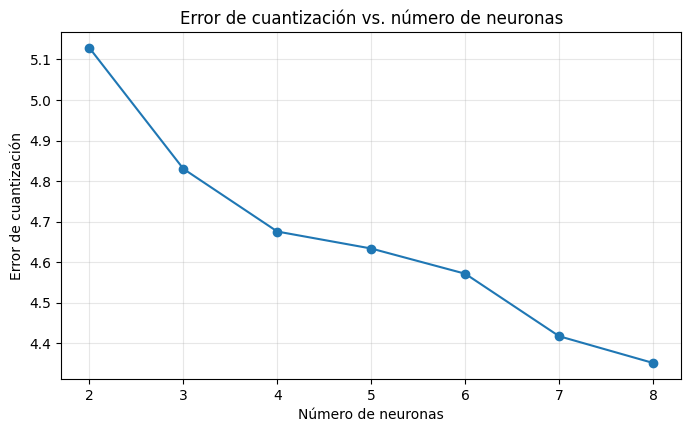

,Error de cuantización,Neuronas muertas,Ventanas por neurona
Neuronas,,,
2,5.1284,0,"[346, 394]"
3,4.8301,0,"[276, 158, 306]"
4,4.6754,0,"[261, 126, 162, 191]"
5,4.6335,0,"[182, 100, 125, 255, 78]"
6,4.5713,0,"[192, 76, 97, 87, 80, 208]"
7,4.4171,0,"[191, 66, 178, 80, 76, 60, 89]"
8,4.3511,0,"[82, 69, 117, 97, 50, 136, 63, 126]"


In [60]:
filas4 = []
for n_c in range(2, 9):
    r_c, g_c = entrenar_som(n_c)
    filas4.append({"Neuronas": n_c,
                   "Error de cuantización": round(r_c.quantization_error(X_train_norm), 4),
                   "Neuronas muertas": int(sum((g_c == j).sum() == 0 for j in range(n_c))),
                   "Ventanas por neurona": np.bincount(g_c, minlength=n_c).tolist()})
tabla_nn4 = pd.DataFrame(filas4).set_index("Neuronas")

plt.figure(figsize=(8, 4.5))
plt.plot(tabla_nn4.index, tabla_nn4["Error de cuantización"], "-o")
plt.xlabel("Número de neuronas"); plt.ylabel("Error de cuantización")
plt.title("Error de cuantización vs. número de neuronas")
plt.grid(alpha=0.3); plt.show()
tabla_nn4

**e) Estabilidad con distintas semillas y efecto de la vecindad σ** (5 neuronas)

Como la inicialización es aleatoria, se repite el entrenamiento con 5 semillas. Después se compara la red competitiva pura (σ = 0.01) con una vecindad grande (σ = 1.0), que convierte la red en un SOM donde las vecinas también se mueven.

In [61]:
filas_sem = []
for s in [0, 1, 2, 3, 42]:
    r_s, g_s = entrenar_som(num_neuronas, semilla=s)
    filas_sem.append({"Semilla": s,
                      "Error de cuantización": round(r_s.quantization_error(X_train_norm), 4),
                      "Ventanas por neurona (ordenadas)": sorted(np.bincount(g_s, minlength=num_neuronas).tolist(), reverse=True)})
tabla_semillas = pd.DataFrame(filas_sem).set_index("Semilla")

filas_sig = []
for sg in [0.01, 0.5, 1.0]:
    r_g, g_g = entrenar_som(num_neuronas, sigma_c=sg)
    filas_sig.append({"sigma": sg,
                      "Error de cuantización": round(r_g.quantization_error(X_train_norm), 4),
                      "Ventanas por neurona": np.bincount(g_g, minlength=num_neuronas).tolist()})
tabla_sigma4 = pd.DataFrame(filas_sig).set_index("sigma")

display(tabla_semillas)
display(tabla_sigma4)

,Error de cuantización,Ventanas por neurona (ordenadas)
Semilla,,
0,4.6206,"[205, 202, 156, 91, 86]"
1,4.5808,"[231, 211, 116, 93, 89]"
2,4.7264,"[254, 185, 109, 105, 87]"
3,4.6040,"[251, 183, 136, 106, 64]"
42,4.6335,"[255, 182, 125, 100, 78]"


,Error de cuantización,Ventanas por neurona
sigma,,
0.01,4.6335,"[182, 100, 125, 255, 78]"
0.50,4.6335,"[125, 100, 78, 182, 255]"
1.00,4.6527,"[240, 91, 223, 86, 100]"


<a id="conclusiones"></a>

## 6. Conclusiones

<a id="conclusiones-personales"></a>

### 6.1 Conclusiones personales

**Dayanni**

Esta práctica me ayudó a ver la diferencia entre las redes que usamos antes y una red competitiva. Aquí no le dimos a la red ninguna respuesta correcta y aun así encontró sola los cuatro grupos: cada neurona terminó en el centro de una nube de puntos. Me llamó la atención lo sencilla que es la regla, porque solo se mueve la neurona más cercana, y aun así funciona muy bien. También aprendí que el resultado depende mucho de cómo se configure la red: si ponemos menos neuronas que grupos, una neurona tiene que cubrir dos nubes, y si ponemos de más o elegimos mal la tasa de aprendizaje, aparecen neuronas que nunca ganan y no sirven para nada. Por eso es importante conocer primero los datos y elegir bien el número de neuronas y la forma de iniciar los pesos.

**Esmer**
 

Las redes competitivas me parecieron una forma muy intuitiva de aprendizaje no supervisado: la idea de que las neuronas "compiten" y la ganadora se vuelve el representante de un grupo es sencilla, pero funciona bien para encontrar patrones que uno no ve a simple vista. Me gustó que no necesitan etiquetas y que cada neurona se puede interpretar directamente como el prototipo de su clase. Aprendí que su resultado depende mucho de cómo se preparan los datos y de los parámetros que uno elige, como el número de neuronas, la tasa de aprendizaje y la inicialización, así que no hay una única respuesta correcta y hay que analizar los grupos con criterio. Creo que son útiles en muchos problemas además de las finanzas, como segmentar clientes, comprimir información o clasificar señales e imágenes cuando no se tienen datos etiquetados.

**Fernanda**

En la Práctica 2 me tocó resolver el mismo tipo de problema que en la Práctica 1, pero con la librería MiniSom, y me sirvió para entender que MiniSom en realidad entrena un mapa autoorganizado y que, al poner una vecindad casi nula (σ = 0.01), se convierte en la red competitiva que programamos a mano. Me gustó ver que, aunque los datos no tenían grupos tan separados, la red colocó cada neurona en el centro de una zona de puntos y que iniciar los pesos con los mismos datos evitó que hubiera neuronas muertas. También aprendí que elegir el número de neuronas no es obvio: con 6 neuronas la red partió las nubes dispersas, y la gráfica del error contra el número de neuronas mostró que en realidad hay 4 grupos naturales. Por último, el dato nuevo quedó casi en la frontera entre dos neuronas, lo que me hizo ver que la clasificación de un punto puede cambiar con la semilla y que siempre hay que revisar las distancias y no solo la neurona ganadora.


**Estephany Herrera**
En la Práctica 4 usé la red competitiva sobre una sola serie de tiempo, el activo BMV_24, cortada en ventanas de 35 días. Lo que más me gustó es que la red encontró sola formas que sí se reconocen en la gráfica del precio: un grupo de alza, uno de baja, uno lateral y dos de transición, y los tramos largos de subida y caída del precio quedaron en el grupo que les correspondía. Aprendí que normalizar cada ventana es clave, porque así la red compara la forma y no el precio, aunque se pierde la magnitud del movimiento. También me di cuenta de que elegir el número de neuronas no tiene una respuesta única: el error siempre baja al agregar neuronas y no hay un codo claro, así que hubo que decidir mirando si los patrones se podían interpretar. Con distintas semillas el error casi no cambió, pero el tamaño de los grupos sí, y la vecindad σ casi no influyó. Mi conclusión es que esta técnica sirve para describir y entender el comportamiento pasado de una serie, pero no para predecir el futuro por sí sola.

<a id="conclusiones-generales"></a>

### 6.2 Conclusiones generales

Las cuatro prácticas muestran cómo funciona una red competitiva, un modelo de aprendizaje no supervisado: no recibe respuestas correctas, las neuronas compiten por cada dato y la ganadora se acerca a él, hasta que cada neurona queda como el prototipo de un grupo.

Lo que se logró: la red encontró los grupos sin etiquetas en los cuatro problemas.
* En la Práctica 1 (programada desde cero), cada una de las 4 neuronas quedó en el centro de su nube y clasificó el dato nuevo.
* En la Práctica 2 (MiniSom con σ casi nula) hizo lo mismo con nubes que se tocan.
* En la Práctica 3 separó 35 activos de la BMV en 4 grupos de comportamiento: alcista, lateral, alcista con estabilización y bajista.
* En la Práctica 4 encontró cinco formas típicas de 35 días en BMV_24 (alza, baja, lateral y dos de transición). Las alzas y bajas coincidieron con los tramos largos de subida y caída del precio.

El número de neuronas es una decisión de quien modela: con menos neuronas que grupos, una neurona cubre dos nubes; con más, aparecen neuronas que nunca ganan o grupos partidos en pedazos. En las Prácticas 2 y 4 el error de cuantización siempre bajó al agregar neuronas, así que no basta mirar el error y hay que revisar si los grupos tienen sentido.
La configuración importa: la tasa de aprendizaje, la inicialización y la semilla cambian el resultado. Iniciar los pesos con puntos de los mismos datos evitó las neuronas muertas. Con distintas semillas la calidad (el error) casi no cambió, pero el tamaño de los grupos sí. Un dato cerca de una frontera puede cambiar de grupo, por lo que conviene revisar las distancias y no solo la neurona ganadora.
MiniSom es un SOM: con una vecindad σ casi nula se comporta como la red competitiva pura de la Práctica 1; con σ grande las neuronas vecinas se jalan entre sí.
Preparar los datos pesa tanto como la red: al normalizar con z-score (por activo en la Práctica 3, por ventana en la 4) la red compara formas y no escalas de precio. A cambio se pierde la magnitud del movimiento.
Limitaciones: hay que decidir cuántos grupos buscar, los grupos son descriptivos (no hay una “respuesta correcta” con la cual compararlos) y en las series de tiempo la clase describe el pasado, no predice lo que sigue.
Aplicaciones: más allá de las finanzas, sirve para segmentar clientes, comprimir información o clasificar señales e imágenes cuando no hay datos etiquetados.